In [1]:
# Instalando o statsforecast
! pip install statsforecast

In [2]:
## Biblioteca para abrir o arquivo do Google Drive
import gdown

# Biblioteca para pegar um número aleatório
import random

## Biblioteca para interação com o sistema
import os
import sys

## Bibliotecas para manipulação dos dados
import pandas as pd
import numpy as np
import datetime
from copy import deepcopy

## Bibliotecas para análise e visualização dos dados
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import statsforecast
from statsforecast import StatsForecast
import sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from xgboost import plot_importance, plot_tree

## Biblioteca para importação dos modelos de machine learning
from statsforecast.models import Naive, AutoARIMA
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers

In [3]:
## Verificando as versões
print(f"python: version {sys.version}")
print(f"gdown: version {gdown.__version__}")
print(f"pandas: version {pd.__version__}")
print(f"numpy: version {np.__version__}")
print(f"matplotlib: version {matplotlib.__version__}")
print(f"seaborn: version {sns.__version__}")
print(f"statsmodels: version {statsmodels.__version__}")
print(f"sklearn: version {sklearn.__version__}")
print(f"statsforecast: version {statsforecast.__version__}")
print(f"xgboost: version {xgb.__version__}")
print(f"tensorflow: version {tf.__version__}")


python: version 3.11.11 (main, Dec  4 2024, 08:55:07) [GCC 11.4.0]
gdown: version 5.2.0
pandas: version 2.2.2
numpy: version 2.0.2
matplotlib: version 3.10.0
seaborn: version 0.13.2
statsmodels: version 0.14.4
sklearn: version 1.6.1
statsforecast: version 2.0.1
xgboost: version 2.1.4
tensorflow: version 2.18.0


In [4]:
## Definindo uma seed para reprodutibilidade
seed = 7

random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# Garantindo reprodutibilidade ao usar GPU
os.environ['PYTHONHASHSEED'] = '7'  # Fixa a seed para hash interno do Python
os.environ['TF_DETERMINISTIC_OPS'] = '1'  # Operações determinísticas no TensorFlow

Os dados para treinamento e teste do modelo foram retirados do site: https://br.investing.com/indices/bovespa-historical-data.


Utilizaremos dados dos últimos 10 anos.


Data inicial: 01/01/2015


Data final: 26/02/2025

In [5]:
## Link para a base de dados no Google Drive
url = f"https://drive.google.com/uc?id=1GeCIXLLmFl_kCY_JNVShIG3QupbQQqPS"

# Baixar o arquivo para o ambiente
output = "data.csv"
gdown.download(url, output, quiet=False)

# Ler o arquivo CSV
df = pd.read_csv(output, sep=';')

Downloading...
From: https://drive.google.com/uc?id=1GeCIXLLmFl_kCY_JNVShIG3QupbQQqPS
To: /content/data.csv
100%|██████████| 138k/138k [00:00<00:00, 67.7MB/s]


In [6]:
df.head()

,Data,Último,Abertura,Máxima,Mínima,Vol.,Var%
0,02/01/2015,48.512,50.004,50.004,48.345,"2,88M","-2,99%"
1,05/01/2015,47.517,48.512,48.512,47.264,"3,87M","-2,05%"
2,06/01/2015,48.001,47.517,48.061,47.338,"4,56M","1,02%"
3,07/01/2015,49.463,48.006,49.882,48.006,"4,41M","3,05%"
4,08/01/2015,49.943,49.463,50.261,49.017,"3,62M","0,97%"


## Análise Inicial


In [7]:
df.shape

(2519, 7)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2519 entries, 0 to 2518
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Data      2519 non-null   object 
 1   Último    2519 non-null   float64
 2   Abertura  2519 non-null   float64
 3   Máxima    2519 non-null   float64
 4   Mínima    2519 non-null   float64
 5   Vol.      2518 non-null   object 
 6   Var%      2519 non-null   object 
dtypes: float64(4), object(3)
memory usage: 137.9+ KB


In [9]:
df.isnull().sum()

,0
Data,0
Último,0
Abertura,0
Máxima,0
Mínima,0
Vol.,1
Var%,0


In [10]:
df[df.isnull().any(axis=1) == True]

,Data,Último,Abertura,Máxima,Mínima,Vol.,Var%
270,10/02/2016,40.377,40.592,40.592,39.96,NaN,"-0,53%"


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Último,2519.0,92.706848,27.141297,37.497,66.9785,100.093,115.4140,137.344
Abertura,2519.0,92.677805,27.146862,37.501,66.9345,100.050,115.3895,137.349
Máxima,2519.0,93.508404,27.256889,38.031,67.5320,101.126,116.4525,137.469
Mínima,2519.0,91.871981,27.023974,37.046,66.2675,99.141,114.6100,136.664


## Transformação dos Dados


In [12]:
## Alterando o nome das colunas para facilitar as trasnformações

df.columns = ['ds', 'y', 'abertura', 'maximo', 'minimo', 'volume', 'variacao_percentual']

In [13]:
## Alterando o tipo da data de "Object" para "Datetime" para conseguir aplicar os modelos

df['ds'] = pd.to_datetime(df['ds'], format='%d/%m/%Y')
df['ds'].dtypes

dtype('<M8[ns]')

In [14]:
## Transformando a coluna de data no index
df.index = df['ds']
df.drop('ds', axis=1, inplace=True)
df.head(3)

,y,abertura,maximo,minimo,volume,variacao_percentual
ds,,,,,,
2015-01-02,48.512,50.004,50.004,48.345,"2,88M","-2,99%"
2015-01-05,47.517,48.512,48.512,47.264,"3,87M","-2,05%"
2015-01-06,48.001,47.517,48.061,47.338,"4,56M","1,02%"


In [15]:
#  Para fazer a previsão do fechamento da Ibovespa dos próximos dias não teriamos o valor maximo, minimo e volume negociado dos dias a serem previstos.
#  Por este motivo iremos utilizar apenas a data (ds) e o fechamento (y).

## Selecionando os dados apenas de y (fechamento) e de data (index)
df = pd.DataFrame(df['y'])

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2519 entries, 2015-01-02 to 2025-02-26
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       2519 non-null   float64
dtypes: float64(1)
memory usage: 39.4 KB


In [17]:
df.head()

,y
ds,
2015-01-02,48.512
2015-01-05,47.517
2015-01-06,48.001
2015-01-07,49.463
2015-01-08,49.943


In [18]:
## Definir a frequência como 'B' (Business Days - Dias Úteis)
df = df.asfreq('B')

In [19]:
## Preencher os valores nulos criados (finais de semana e feriados) pelo valor da linha anterior
df = df.ffill()

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2649 entries, 2015-01-02 to 2025-02-26
Freq: B
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       2649 non-null   float64
dtypes: float64(1)
memory usage: 41.4 KB


In [21]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
y,2649.0,92.64572,27.144258,37.497,66.968,100.011,115.488,137.344


## Visualizações

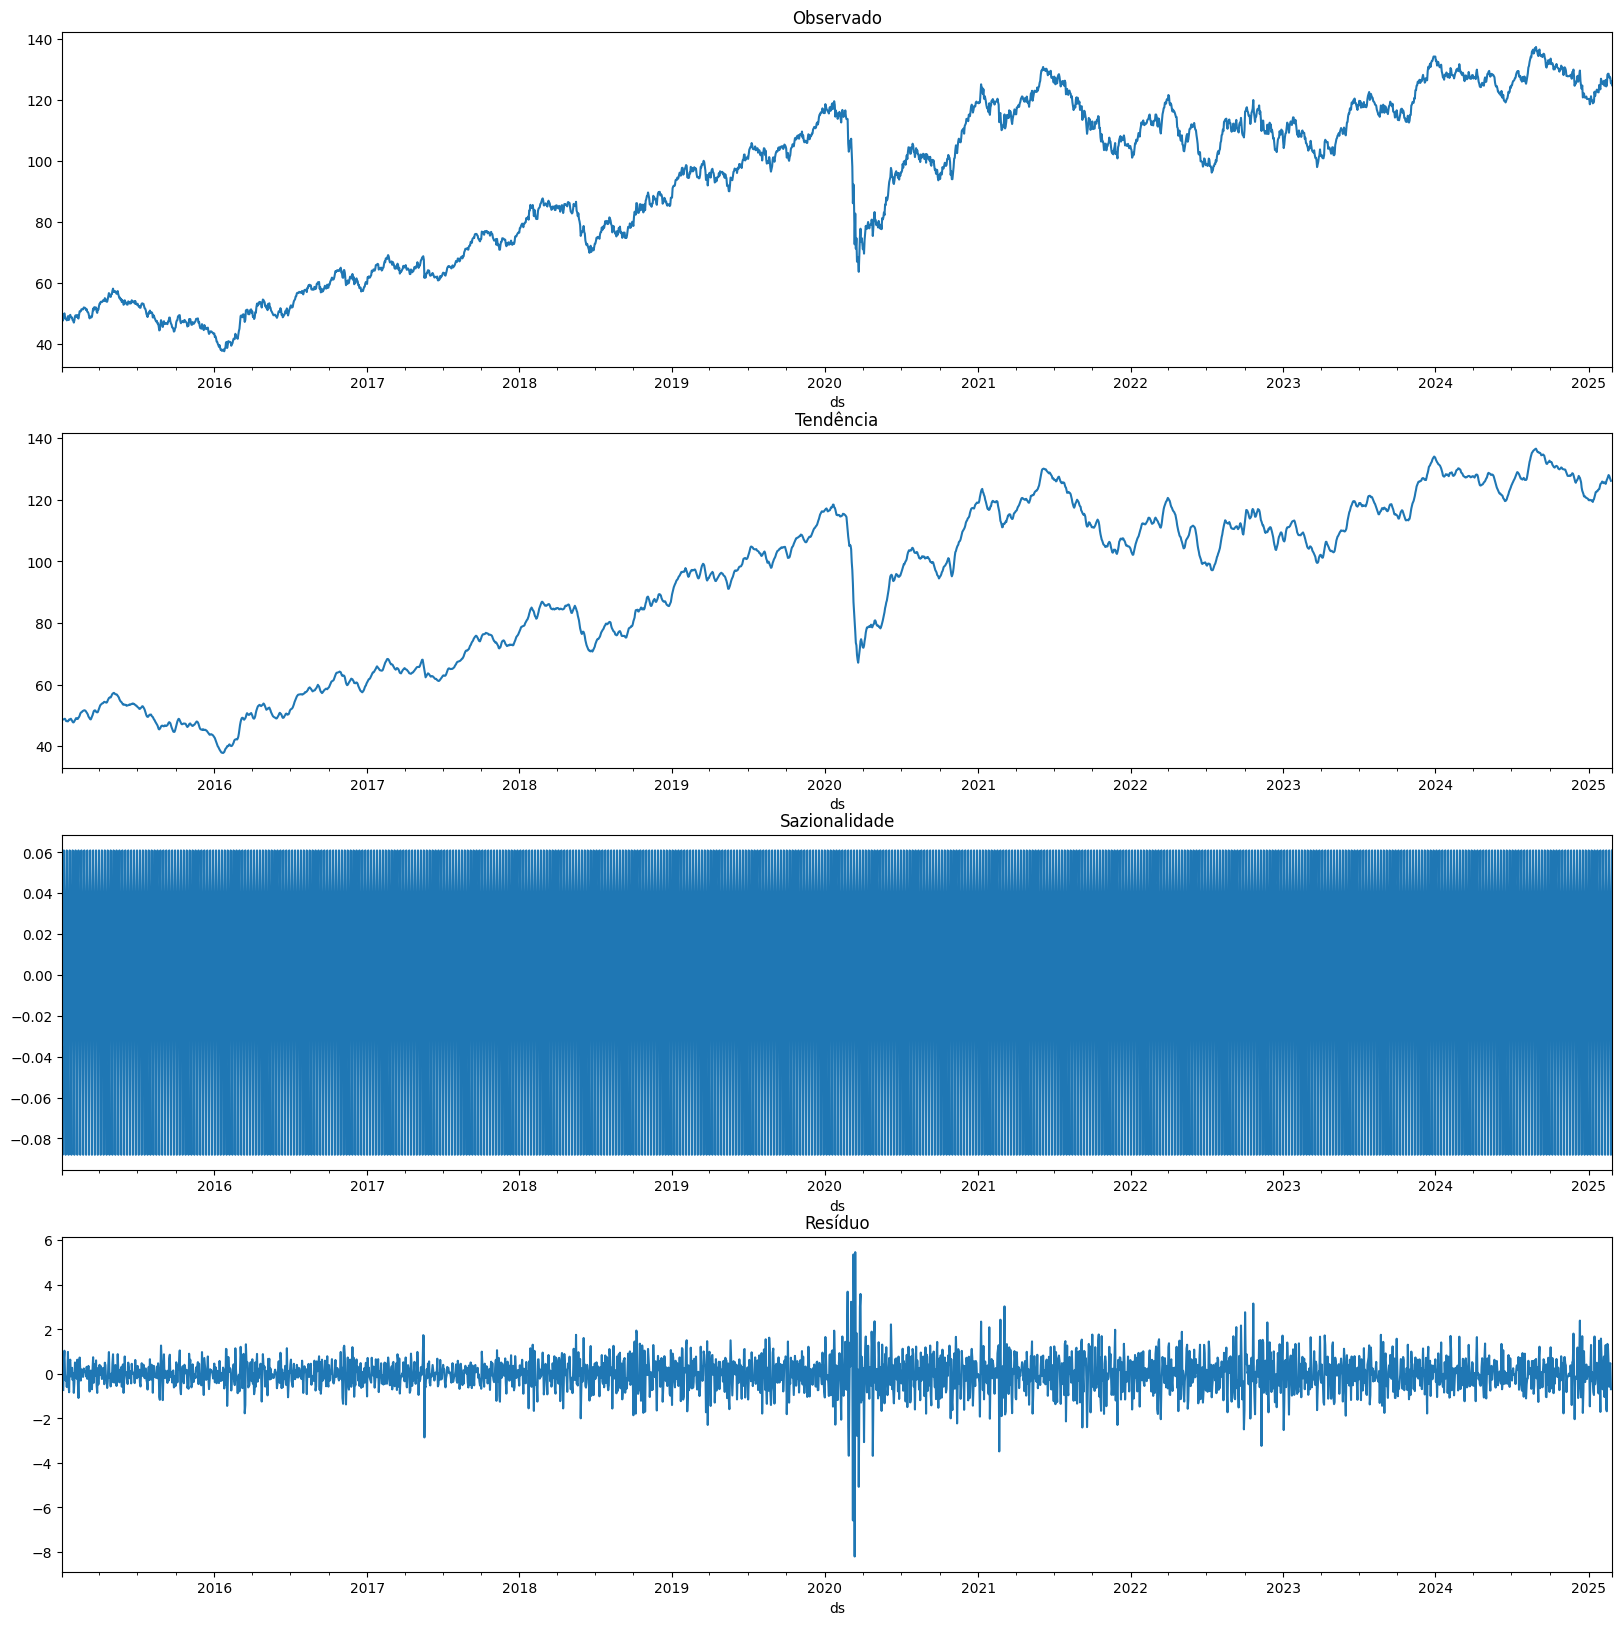

In [22]:
## Análisando a tendência, sazionalidade e resíduos da série temporal no modelo aditivo
decomposicao_temporal_add = seasonal_decompose(df['y'], model='additive')

fig, ax = plt.subplots(4, 1, figsize=(20,20))

decomposicao_temporal_add.observed.plot(ax=ax[0])
ax[0].set_title('Observado')

decomposicao_temporal_add.trend.plot(ax=ax[1])
ax[1].set_title('Tendência')

decomposicao_temporal_add.seasonal.plot(ax=ax[2])
ax[2].set_title('Sazionalidade')

decomposicao_temporal_add.resid.plot(ax=ax[3])
ax[3].set_title('Resíduo')

plt.show()

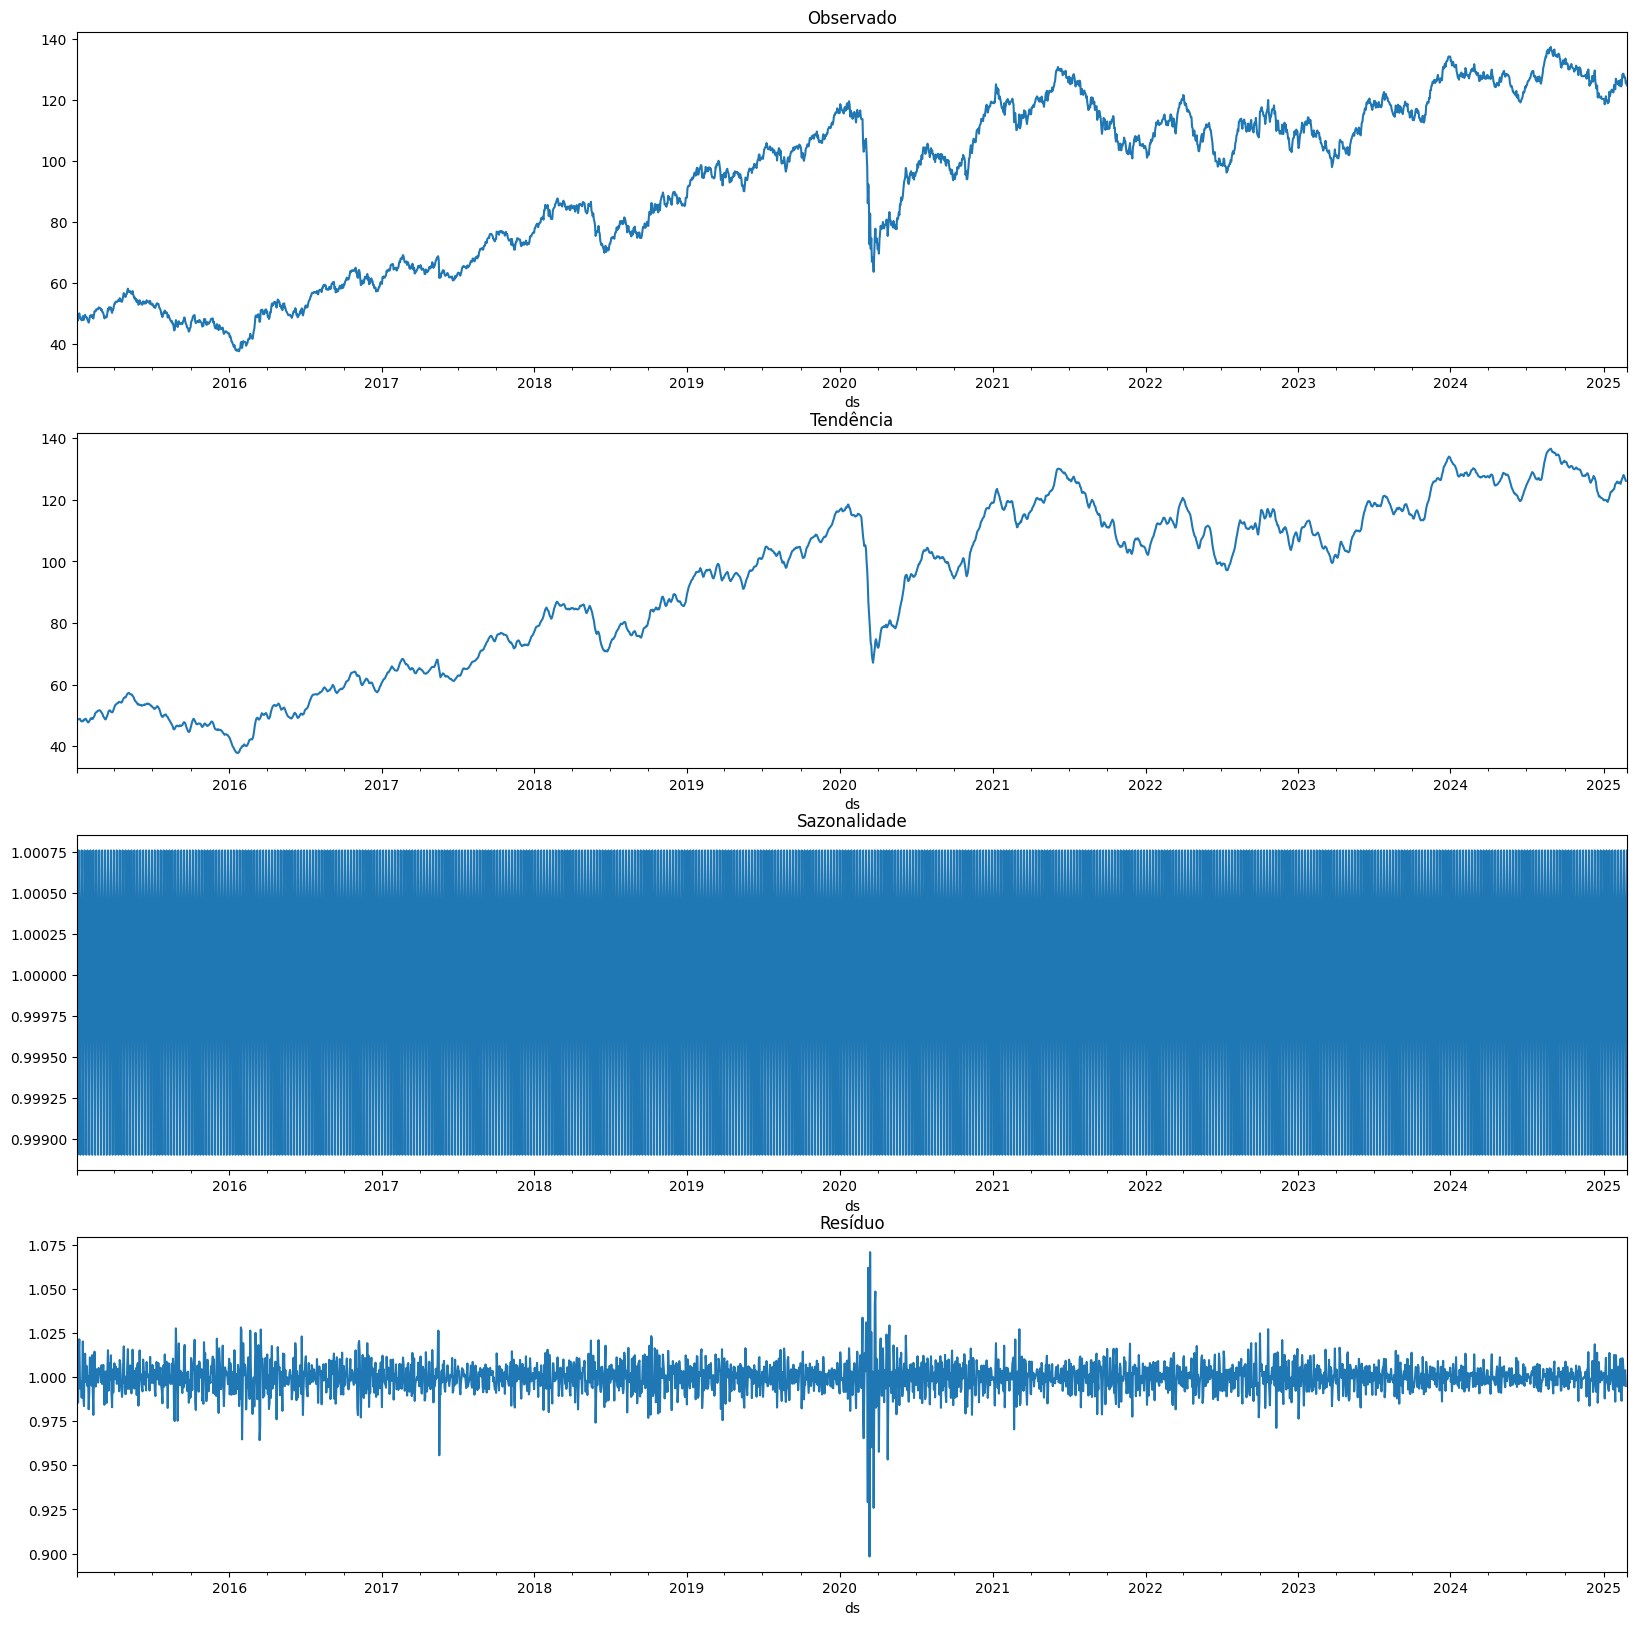

In [23]:
## Análisando a tendência, sazionalidade e resíduos da série temporal no modelo multiplicativo
decomposicao_temporal_mult = seasonal_decompose(df['y'], model='multiplicative')

fig, ax = plt.subplots(4, 1, figsize=(20,20))

decomposicao_temporal_mult.observed.plot(ax=ax[0])
ax[0].set_title('Observado')

decomposicao_temporal_mult.trend.plot(ax=ax[1])
ax[1].set_title('Tendência')

decomposicao_temporal_mult.seasonal.plot(ax=ax[2])
ax[2].set_title('Sazonalidade')

decomposicao_temporal_mult.resid.plot(ax=ax[3])
ax[3].set_title('Resíduo')

plt.show()

In [24]:
## Verificar a estacionáridade da série temporal  (P-Value < 0.0)
x = df.values
teste_adfuller = adfuller(x)

print('Teste ADF')
print(f'Teste Estatístico: {teste_adfuller[0]}')
print(f'P-Value: {teste_adfuller[1]}')
print('Valores críticos:')

for key, value in teste_adfuller[4].items():
  print(f'\t{key}: {value}')

Teste ADF
Teste Estatístico: -1.5438670383407649
P-Value: 0.5117102154453417
Valores críticos:
	1%: -3.432834129730111
	5%: -2.862637500037151
	10%: -2.56735423758412


### Análise dos resultados:
*  Série Temporal não estacionária
*  Tendência de crescimento
*  Possui sazionalidade mas não é significativa. (Baixíssima amplitude)









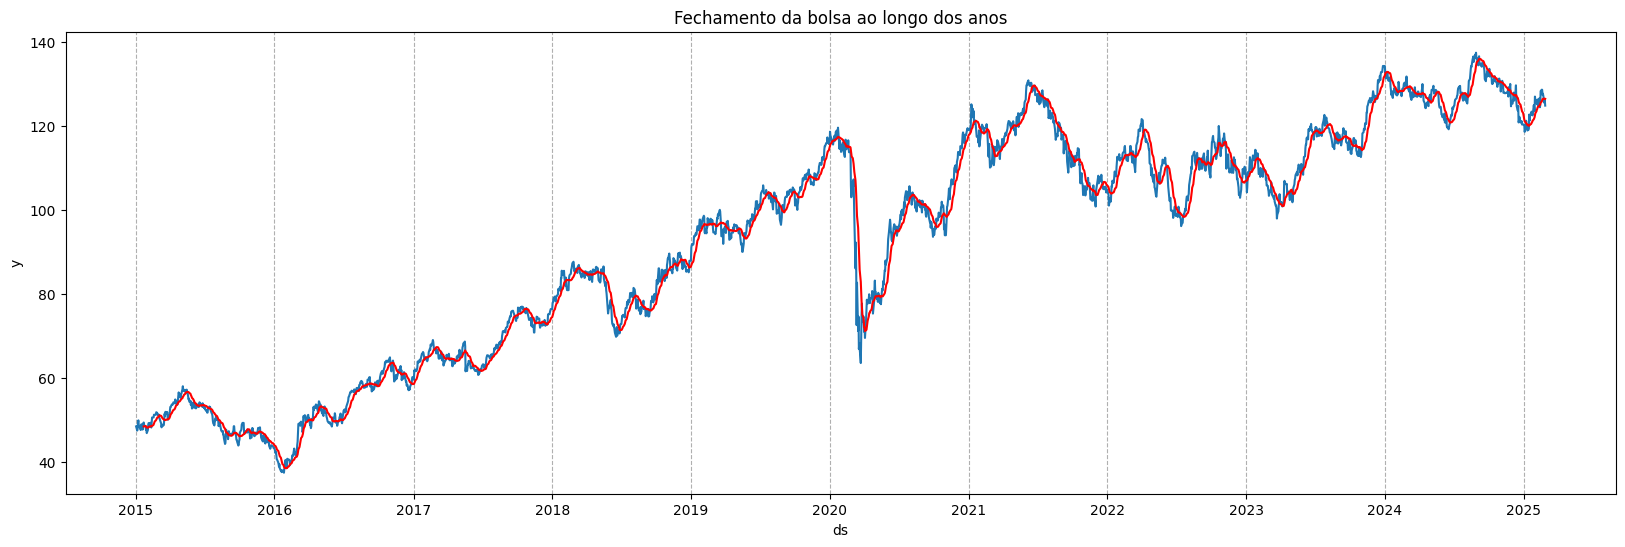

In [25]:
## Criando a janela de tempo a ser análisada (lag)
lag = 15

## Atribiuindo a média móvel
ma = pd.DataFrame(df.rolling(lag).mean())

## Vizualiando a média móvel e o valor de fechamento
fig, ax = plt.subplots(figsize=(20,6))

sns.lineplot(df, x=df.index, y='y', legend='auto', ax=ax)
sns.lineplot(ma, x=ma.index, y='y', legend='auto', ax=ax, color='red')

# Configurar os ticks do eixo X para serem anuais
plt.gca().xaxis.set_major_locator(mdates.YearLocator())  # Ticks anuais
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # Mostrar apenas o ano

plt.grid(axis='x', linestyle='--')
ax.set_title("Fechamento da bolsa ao longo dos anos")

plt.show()

Teste ADF
Teste Estatístico: -13.271464929433606
P-Value: 8.02155733562791e-25
Valores críticos:
	1%: -3.432834129730111
	5%: -2.862637500037151
	10%: -2.56735423758412


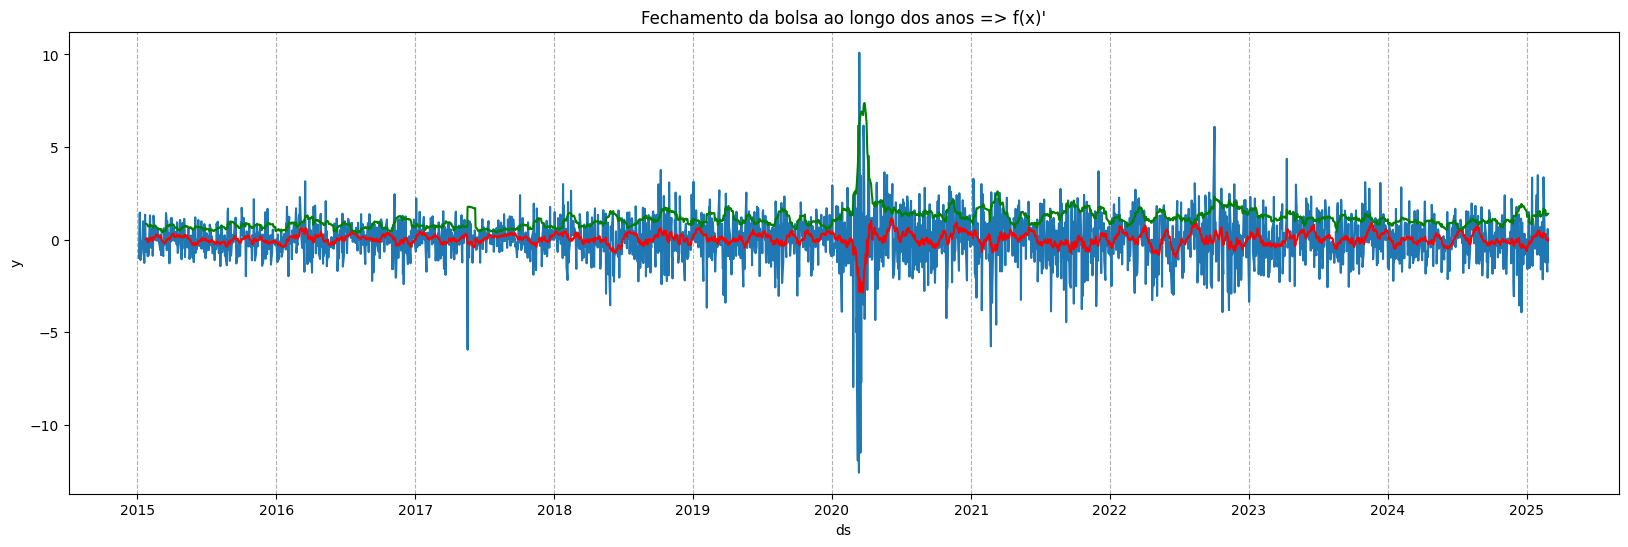

In [26]:
## Aplicando diferenciação para aproximar o P-Value = 0 transformando a série temporária em estacionária
df_diff_1 = pd.DataFrame(df['y'].diff(1).dropna())

ma_diff_1 = df_diff_1.rolling(lag).mean()

std_diff_1 = df_diff_1.rolling(lag).std()

## Visualizando as transformações
fig, ax = plt.subplots(figsize=(20,6))

sns.lineplot(df_diff_1, x=df_diff_1.index, y='y', legend=False, ax=ax)
sns.lineplot(ma_diff_1, x=ma_diff_1.index, y='y', legend=False, ax=ax, color='red')
sns.lineplot(std_diff_1, x=std_diff_1.index, y='y', legend=False, ax=ax, color='green')

# Configurar os ticks do eixo X para serem anuais
plt.gca().xaxis.set_major_locator(mdates.YearLocator())  # Ticks anuais
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # Mostrar apenas o ano

plt.grid(axis='x', linestyle='--')
ax.set_title("Fechamento da bolsa ao longo dos anos => f(x)'")


## Verificar a estacionáridade da série temporal após a diferenciação  (P-Value < 0.05)
x_diff_1 = df_diff_1['y'].values

teste_adfuller_diff_1 = adfuller(x_diff_1)

print('Teste ADF')
print(f'Teste Estatístico: {teste_adfuller_diff_1[0]}')
print(f'P-Value: {teste_adfuller_diff_1[1]}')
print('Valores críticos:')

for key, value in teste_adfuller_diff_1[4].items():
  print(f'\t{key}: {value}')

## Plota o gráfico
plt.show()

In [27]:
## Avaliando a Autocorrelação (ACF) e Autocorrelação Parcial (PACF) do dataframe diferenciado

## Autocorrelação (ACF)
lag_acf = acf(df_diff_1, nlags=100)

## Autocorrelação Parcial (PACF)
lag_pacf = pacf(df_diff_1, nlags=100)

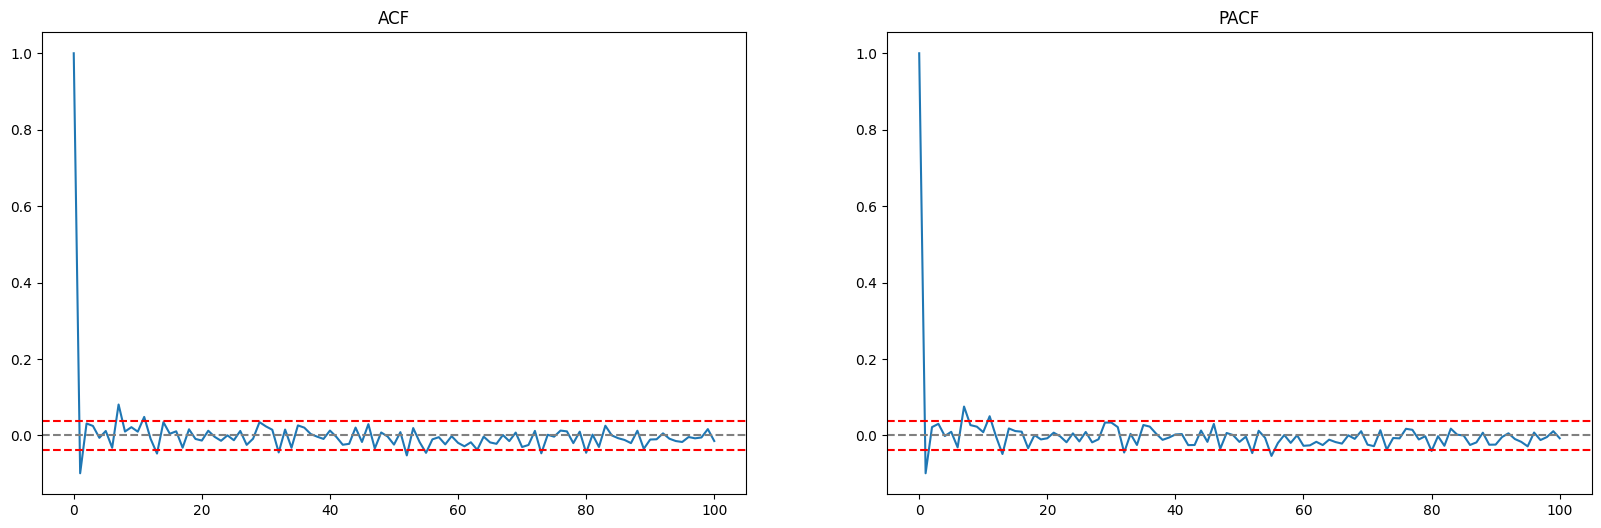

In [28]:
## Visualizando os gráifcos de ACF e PACF da série diferenciada
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

## ACF
ax[0].plot(lag_acf)
ax[0].axhline(y=-1.96/(np.sqrt(len(df_diff_1)-1)), linestyle='--', color='red')
ax[0].axhline(y=0, linestyle='--', color='gray')
ax[0].axhline(y=1.96/(np.sqrt(len(df_diff_1)-1)), linestyle='--', color='red')
ax[0].set_title('ACF')

## PACF
ax[1].plot(lag_pacf)
ax[1].axhline(y=-1.96/(np.sqrt(len(df_diff_1)-1)), linestyle='--', color='red')
ax[1].axhline(y=0, linestyle='--', color='gray')
ax[1].axhline(y=1.96/(np.sqrt(len(df_diff_1)-1)), linestyle='--', color='red')
ax[1].set_title('PACF')

plt.show()

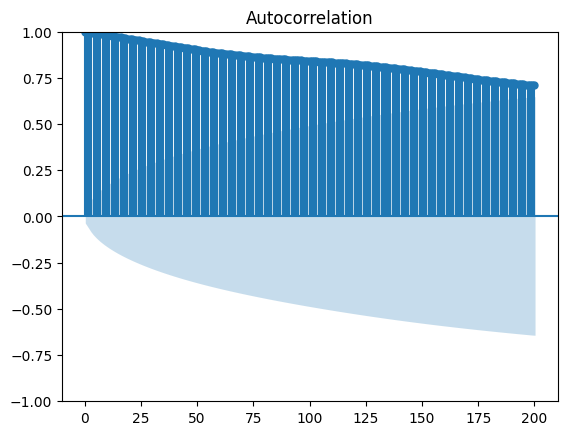

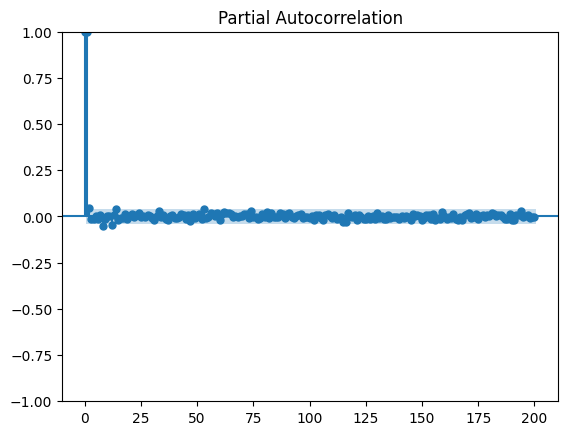

In [29]:
## Visualizando os gráifcos de ACF e PACF da série sem transformações
plot_acf(df['y'].values, lags=200)
plot_pacf(df['y'].values, lags=200)
plt.show()

array([[<Axes: title={'center': 'y'}>]], dtype=object)

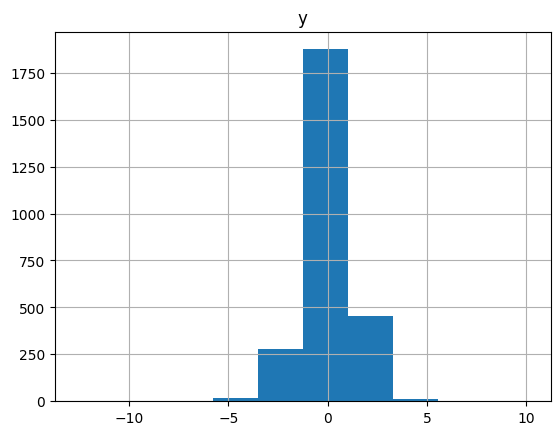

In [30]:
df_diff_1.hist()

## Criando o algorítmo de machine learning

In [31]:
## Criando o dataframe para os algorítimos NAIVE e ARIMA com o Statsforecast
df_unico = df.reset_index()

## Criando a coluna "unique_id", necessária para treinar os modelos com o Statsforecast
df_unico['unique_id'] = 1

In [32]:
## Definindo o level de precisão do algorítimo e o tamanho do dataframe de validação e de teste
global total_de_dias
total_de_dias = 10

A escolha de 10 dias como horizonte de previsão equilibra precisão e utilidade, capturando tendências de curto prazo sem comprometer a qualidade da previsão. Previsões mais longas tendem a apresentar maior erro, enquanto períodos muito curtos podem deixar de capturar movimentos relevantes. Esse intervalo atende bem traders e investidores, permitindo reagir a tendências de curto prazo e otimizar decisões de compra e venda.

In [33]:
## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_unico) - (total_de_dias * 2)
tamanho_treino_teste = len(df_unico) - total_de_dias


## Criando os dataframes com os dados de validação
treino_validacao = df_unico.iloc[:tamanho_treino_validacao]
print(f'Total de dados para treinamento com dados de validação: {len(treino_validacao)}')

validacao = df_unico.iloc[tamanho_treino_validacao:tamanho_treino_teste]
print(f'Total de dados para teste: {len(validacao)}')

## Criando os dataframes com os dados de teste
treino_teste = df_unico.iloc[:tamanho_treino_teste]
print(f'Total de dados para treinamento com dados de teste: {len(treino_teste)}')

teste = df_unico.iloc[tamanho_treino_teste:]
print(f'Total de dados para teste: {len(teste)}')

h_teste = len(teste)
h_validacao = len(validacao)

Total de dados para treinamento com dados de validação: 2629
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2639
Total de dados para teste: 10


In [34]:
## Criando um dataframe com os valores de teste para avaliar o erro de cada modelo
global resultado_teste
resultado_teste = teste[['ds', 'y']]


## Criando um dataframe com os valores de teste para avaliar o erro de cada modelo
global resultado_validacao
resultado_validacao = validacao[['ds', 'y']]

In [35]:
resultado_validacao.tail()

,ds,y
2634,2025-02-06,126.225
2635,2025-02-07,124.619
2636,2025-02-10,125.572
2637,2025-02-11,126.522
2638,2025-02-12,124.380


In [36]:
validacao.tail()

,ds,y,unique_id
2634,2025-02-06,126.225,1
2635,2025-02-07,124.619,1
2636,2025-02-10,125.572,1
2637,2025-02-11,126.522,1
2638,2025-02-12,124.380,1


In [37]:
## Função para verificar a precisão (accuracy) do modelo
def wmape(y_test, y_pred):
  return np.abs((y_test-y_pred).sum()) / np.abs(y_test).sum()

In [38]:
## Criando a função para treinar e testar os modelos NAIVE e ARIMA
def treina_e_testa_modelo_statsforecast(modelo, level, nome_modelo):
  global resultado_teste
  global resultado_validacao

  # Criando e treinando o modelo com os dados de validacao
  model_validacao = StatsForecast(models=[modelo], freq='B', n_jobs=-1)
  model_validacao.fit(treino_validacao)

  # Criando e treinando o modelo com os dados de teste
  model_teste = StatsForecast(models=[modelo], freq='B', n_jobs=-1)
  model_teste.fit(treino_teste)

  # Realizando a previsão do modelo com os dados de validação
  df_forecast_validacao = model_validacao.predict(h=h_validacao, level=[level])
  df_forecast_validacao = df_forecast_validacao.reset_index(drop=True).merge(validacao, on=['ds', 'unique_id'], how='left')

  # Realizando a previsão do modelo com os dados de teste
  df_forecast_teste = model_teste.predict(h=h_teste, level=[level])
  df_forecast_teste = df_forecast_teste.reset_index(drop=True).merge(teste, on=['ds', 'unique_id'], how='left')

  # Realiza a inclusão dos valores de validação preditos ao dataframe de resultados
  resultado_validacao = resultado_validacao.merge(df_forecast_validacao[['ds', nome_modelo]], on='ds', how='left')

  # Realiza a inclusão dos valores de teste preditos ao dataframe de resultados
  resultado_teste = resultado_teste.merge(df_forecast_teste[['ds', nome_modelo]], on='ds', how='left')

In [39]:
## Criando uma função para calcular o erro de cada modelo e plotar os resultados

# Verificando o erro para cada modelo testado
def plota_graficos_e_erros(resultado, tipo_resultado):
  global total_de_dias

  # Criando uma lista com os modelos testados
  modelos = resultado.columns[2:].tolist()

  # Criando uma lista para armazenar os erros de cada modelo
  erros = []

  # Verificando o erro para cada modelo testado
  for modelo in modelos:
      wmape_valor = wmape(resultado['y'].values, resultado[modelo].values)
      mae_valor = mean_absolute_error(resultado['y'].values, resultado[modelo].values)
      mse_valor = mean_squared_error(resultado['y'].values, resultado[modelo].values)
      mape_valor = 100 * mean_absolute_percentage_error(resultado['y'].values, resultado[modelo].values)

      erros.append({
          'Modelo': modelo,
          'WMAPE': wmape_valor,
          'MAE': mae_valor,
          'MSE': mse_valor,
          'MAPE (%)': mape_valor
      })

  # Mostra os erros de cada modelo testado
  df_erros = pd.DataFrame(erros)
  print(df_erros)

  # Criando gráficos para cada modelo
  fig, ax = plt.subplots(len(modelos), 1, figsize=(14, (len(modelos)*2)))

  # Certificando-se de que `ax` seja um array
  if len(modelos) == 1:
      ax = [ax]

  for i, modelo in enumerate(modelos):
      # Plotando os gráficos de cada modelo
      ax[i].plot(resultado['ds'], resultado[modelo], label=modelo, color='blue')
      ax[i].plot(resultado['ds'], resultado['y'], label='Real', linestyle='--', color='red')

      # Definindo título, rótulos e legendas
      ax[i].set_title(f'Fechamento x Previsão dos últimos {total_de_dias} dias - Modelo: {modelo} - Dados de {tipo_resultado}', fontsize=12)
      ax[i].set_xlabel('Data', fontsize=10)
      ax[i].set_ylabel('Fechamento', fontsize=10)
      ax[i].legend(loc='upper left')

  plt.tight_layout()  # Ajusta o layout para evitar sobreposição
  plt.show()

In [40]:
## Criando o modelo 'baseline'
## Modelo Naive
treina_e_testa_modelo_statsforecast(Naive(), 95, 'Naive')

  Modelo     WMAPE     MAE       MSE  MAPE (%)
0  Naive  0.018056  2.2697  5.746086  1.801923


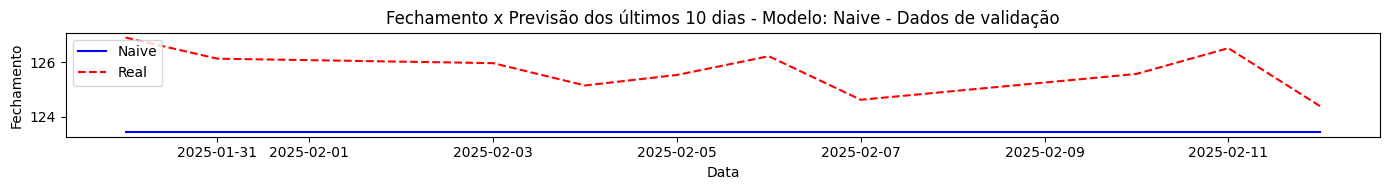

In [41]:
plota_graficos_e_erros(resultado_validacao, 'validação')

In [42]:
## Criando o modelo AutoARIMA que verifica os melhores parâmetros automaticamente
## Modelo AutoARIMA
treina_e_testa_modelo_statsforecast(AutoARIMA(), 95, 'AutoARIMA')

      Modelo     WMAPE       MAE       MSE  MAPE (%)
0      Naive  0.018056  2.269700  5.746086  1.801923
1  AutoARIMA  0.016594  2.085902  4.984245  1.655583


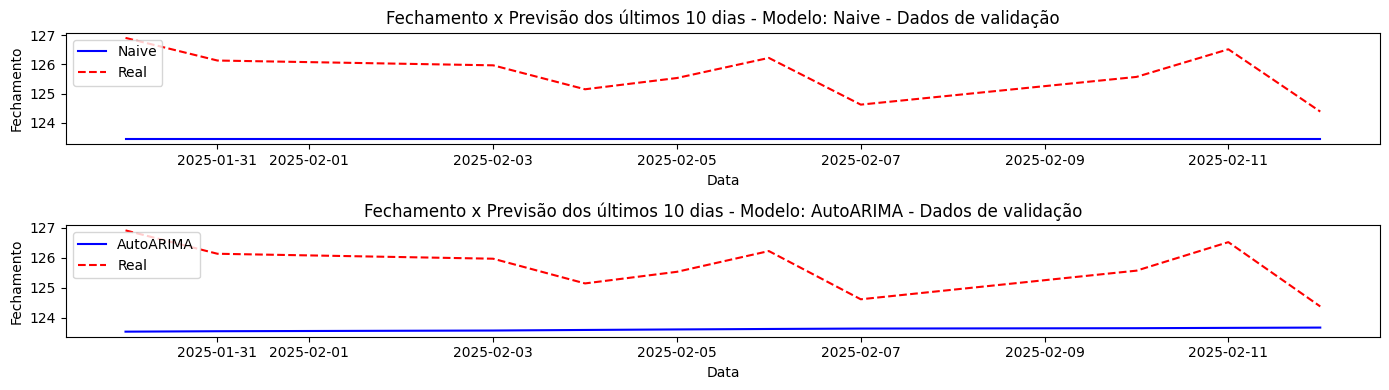

In [43]:
plota_graficos_e_erros(resultado_validacao, 'validação')

In [44]:
## Criação da base para treino do algorito XGBoost
df_xgboost = df.copy()
df_xgboost['dayofweek'] = df_xgboost.index.dayofweek
df_xgboost['quarter'] = df_xgboost.index.quarter
df_xgboost['month'] = df_xgboost.index.month
df_xgboost['year'] = df_xgboost.index.year
df_xgboost['dayofyear'] = df_xgboost.index.dayofyear
df_xgboost['dayofmonth'] = df_xgboost.index.day
df_xgboost.head()

,y,dayofweek,quarter,month,year,dayofyear,dayofmonth
ds,,,,,,,
2015-01-02,48.512,4,1,1,2015,2,2
2015-01-05,47.517,0,1,1,2015,5,5
2015-01-06,48.001,1,1,1,2015,6,6
2015-01-07,49.463,2,1,1,2015,7,7
2015-01-08,49.943,3,1,1,2015,8,8


In [45]:
## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_xgboost) - (total_de_dias * 2)
tamanho_treino_teste = len(df_xgboost) - total_de_dias


## Criando os dataframes com os dados de validação
treino_validacao = df_xgboost.iloc[:tamanho_treino_validacao]
print(f'Total de dados para treinamento com dados de validação: {len(treino_validacao)}')

validacao = df_xgboost.iloc[tamanho_treino_validacao:tamanho_treino_teste]
print(f'Total de dados para teste: {len(validacao)}')

## Criando os dataframes com os dados de teste
treino_teste = df_xgboost.iloc[:tamanho_treino_teste]
print(f'Total de dados para treinamento com dados de teste: {len(treino_teste)}')

teste = df_xgboost.iloc[tamanho_treino_teste:]
print(f'Total de dados para teste: {len(teste)}')

Total de dados para treinamento com dados de validação: 2629
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2639
Total de dados para teste: 10


In [46]:
teste.tail()

,y,dayofweek,quarter,month,year,dayofyear,dayofmonth
ds,,,,,,,
2025-02-20,127.601,3,1,2,2025,51,20
2025-02-21,127.128,4,1,2,2025,52,21
2025-02-24,125.401,0,1,2,2025,55,24
2025-02-25,125.980,1,1,2,2025,56,25
2025-02-26,124.769,2,1,2,2025,57,26


In [47]:
## Verificando as colunas para criar as features e a variável alvo (target)
df_xgboost.columns

Index(['y', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear',
       'dayofmonth'],
      dtype='object')

In [48]:
## Definindo as features e variável alvo (target)
FEATURES = ['dayofweek', 'quarter', 'month', 'year',
       'dayofyear', 'dayofmonth']
TARGET = 'y'

In [49]:
## Criando os dataframes de teste, treino e validação
X_train_test = treino_teste[FEATURES]
y_train_test = treino_teste[TARGET]

X_test = teste[FEATURES]
y_test = teste[TARGET]

X_train_val = treino_validacao[FEATURES]
y_train_val = treino_validacao[TARGET]

X_val = validacao[FEATURES]
y_val = validacao[TARGET]

In [50]:
## Criando a função para treinar o modelo XGB

def treina_e_testa_modelo_xgb(modelo, X_train, X_test, y_train, y_test):
  # Treinando o modelo
  modelo.fit(X_train, y_train,
          eval_set=[(X_train, y_train), (X_test, y_test)],
          verbose=100
          )

  # Visualizando a importancia de cada feature no modelo
  print(pd.DataFrame(data=modelo.feature_importances_,
             index=modelo.feature_names_in_,
             columns=['importance']).sort_values(by='importance')
  )
  return modelo.predict(X_test)

In [51]:
## Treinando e testando o modelo XGBOOST
# Primeira Iteração
reg = xgb.XGBRegressor(objective='reg:squarederror',
                       n_estimators=1200,
                       early_stopping_rounds=50,
                       learning_rate = 0.01,
                       max_dephts=6)

resultado_validacao['XGBoost_1'] = treina_e_testa_modelo_xgb(reg, X_train_val, X_val, y_train_val, y_val)

[0]	validation_0-rmse:26.81959	validation_1-rmse:33.04386


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [21:40:32] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "max_dephts" } are not used.

  warnings.warn(smsg, UserWarning)


[100]	validation_0-rmse:10.36588	validation_1-rmse:14.85990
[200]	validation_0-rmse:4.62882	validation_1-rmse:7.75069
[300]	validation_0-rmse:2.82714	validation_1-rmse:4.68244
[400]	validation_0-rmse:1.85311	validation_1-rmse:3.55391
[500]	validation_0-rmse:1.55597	validation_1-rmse:3.06855
[600]	validation_0-rmse:1.44753	validation_1-rmse:2.98840
[681]	validation_0-rmse:1.30672	validation_1-rmse:2.98395
            importance
dayofweek     0.000134
dayofmonth    0.000433
quarter       0.008353
month         0.017144
dayofyear     0.021500
year          0.952437


      Modelo     WMAPE       MAE       MSE  MAPE (%)
0      Naive  0.018056  2.269700  5.746086  1.801923
1  AutoARIMA  0.016594  2.085902  4.984245  1.655583
2  XGBoost_1  0.022925  2.881770  8.821457  2.289184


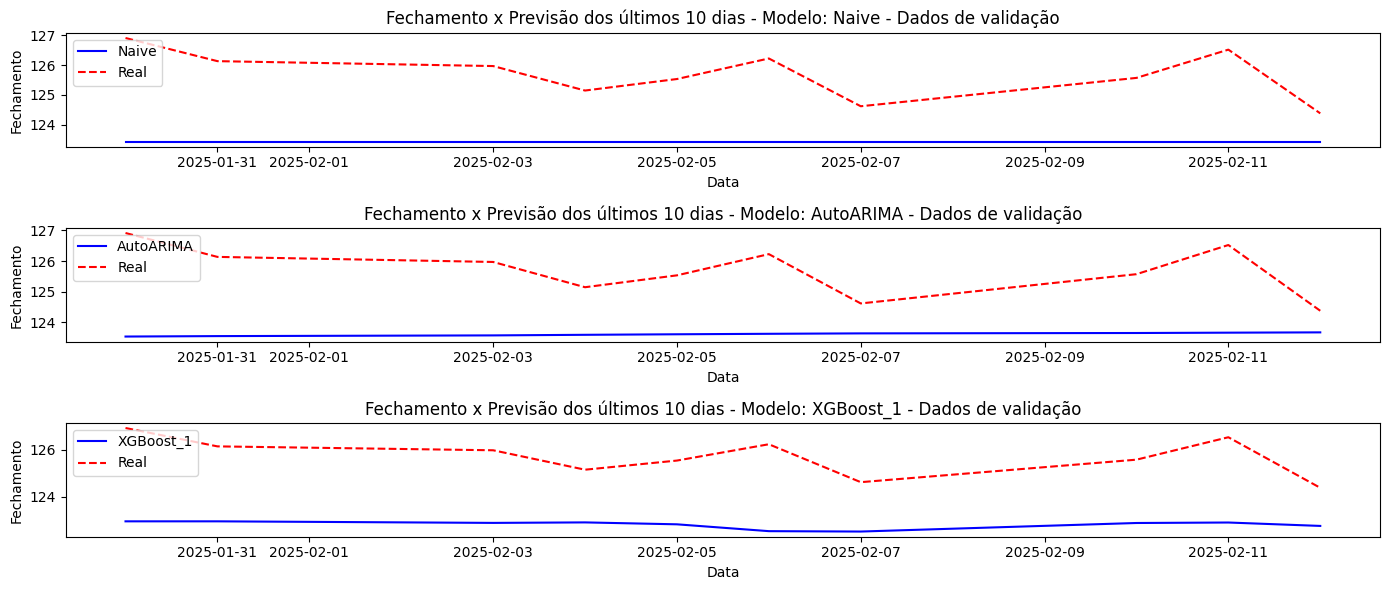

In [52]:
plota_graficos_e_erros(resultado_validacao, 'validação')

In [53]:
## Treinando e testando o modelo XGBOOST
# Segunda Iteração
reg = xgb.XGBRegressor(objective='reg:squarederror',
                       n_estimators=1200,
                       early_stopping_rounds=50,
                       learning_rate = 0.01,
                       max_depth=7 # Aumentando a profundidade da árvore de decisão para 7
                       )

resultado_validacao['XGBoost_2'] = treina_e_testa_modelo_xgb(reg, X_train_val, X_val, y_train_val, y_val)

[0]	validation_0-rmse:26.81864	validation_1-rmse:33.04386
[100]	validation_0-rmse:10.28185	validation_1-rmse:14.82484
[200]	validation_0-rmse:4.28429	validation_1-rmse:7.71183
[300]	validation_0-rmse:2.19101	validation_1-rmse:5.03695
[400]	validation_0-rmse:1.47132	validation_1-rmse:4.11119
[500]	validation_0-rmse:1.16762	validation_1-rmse:3.82890
[600]	validation_0-rmse:1.04233	validation_1-rmse:3.74367
[700]	validation_0-rmse:0.96504	validation_1-rmse:3.64234
[800]	validation_0-rmse:0.89316	validation_1-rmse:3.58316
[900]	validation_0-rmse:0.83169	validation_1-rmse:3.57087
[1000]	validation_0-rmse:0.78407	validation_1-rmse:3.50120
[1044]	validation_0-rmse:0.75010	validation_1-rmse:3.53556
            importance
dayofweek     0.000182
dayofmonth    0.000582
quarter       0.003466
month         0.004909
dayofyear     0.024655
year          0.966206


      Modelo     WMAPE       MAE        MSE  MAPE (%)
0      Naive  0.018056  2.269700   5.746086  1.801923
1  AutoARIMA  0.016594  2.085902   4.984245  1.655583
2  XGBoost_1  0.022925  2.881770   8.821457  2.289184
3  XGBoost_2  0.027269  3.427699  12.242892  2.723634


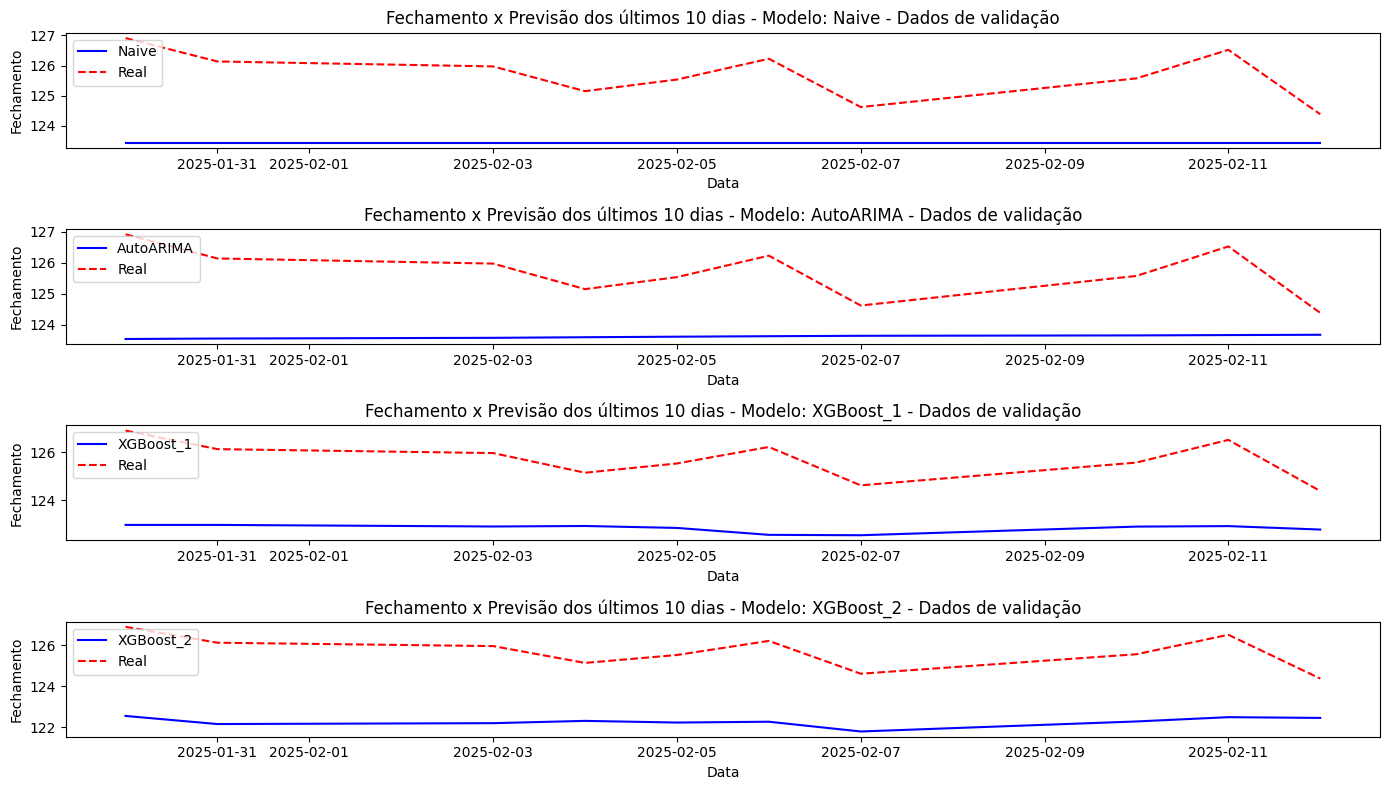

In [54]:
plota_graficos_e_erros(resultado_validacao, 'validação')

Aumentar o número de max_depths para 7 aumentou o erro do modelo

In [55]:
## Treinando e testando o modelo XGBOOST
# Terceira Iteração
reg = xgb.XGBRegressor(objective='reg:squarederror',
                       n_estimators=1200,
                       early_stopping_rounds=50,
                       learning_rate = 0.01,
                       max_depth=5 # Diminuindo a profundidade da árvore de decisão para 5
                       )

resultado_validacao['XGBoost_3'] = treina_e_testa_modelo_xgb(reg, X_train_val, X_val, y_train_val, y_val)

[0]	validation_0-rmse:26.82151	validation_1-rmse:33.04386
[100]	validation_0-rmse:10.56744	validation_1-rmse:13.82417
[200]	validation_0-rmse:4.98416	validation_1-rmse:6.51387
[300]	validation_0-rmse:3.26196	validation_1-rmse:4.35586
[400]	validation_0-rmse:2.78290	validation_1-rmse:3.75606
[500]	validation_0-rmse:2.33056	validation_1-rmse:3.38882
[600]	validation_0-rmse:2.05485	validation_1-rmse:3.09803
[700]	validation_0-rmse:1.95745	validation_1-rmse:2.85134
[800]	validation_0-rmse:1.79137	validation_1-rmse:2.79614
[900]	validation_0-rmse:1.68911	validation_1-rmse:2.71531
[1000]	validation_0-rmse:1.57597	validation_1-rmse:2.61087
[1094]	validation_0-rmse:1.52705	validation_1-rmse:2.59507
            importance
dayofweek     0.000167
dayofmonth    0.000684
month         0.014741
quarter       0.024519
dayofyear     0.031636
year          0.928253


      Modelo     WMAPE       MAE        MSE  MAPE (%)
0      Naive  0.018056  2.269700   5.746086  1.801923
1  AutoARIMA  0.016594  2.085902   4.984245  1.655583
2  XGBoost_1  0.022925  2.881770   8.821457  2.289184
3  XGBoost_2  0.027269  3.427699  12.242892  2.723634
4  XGBoost_3  0.019750  2.482612   6.709853  1.971782


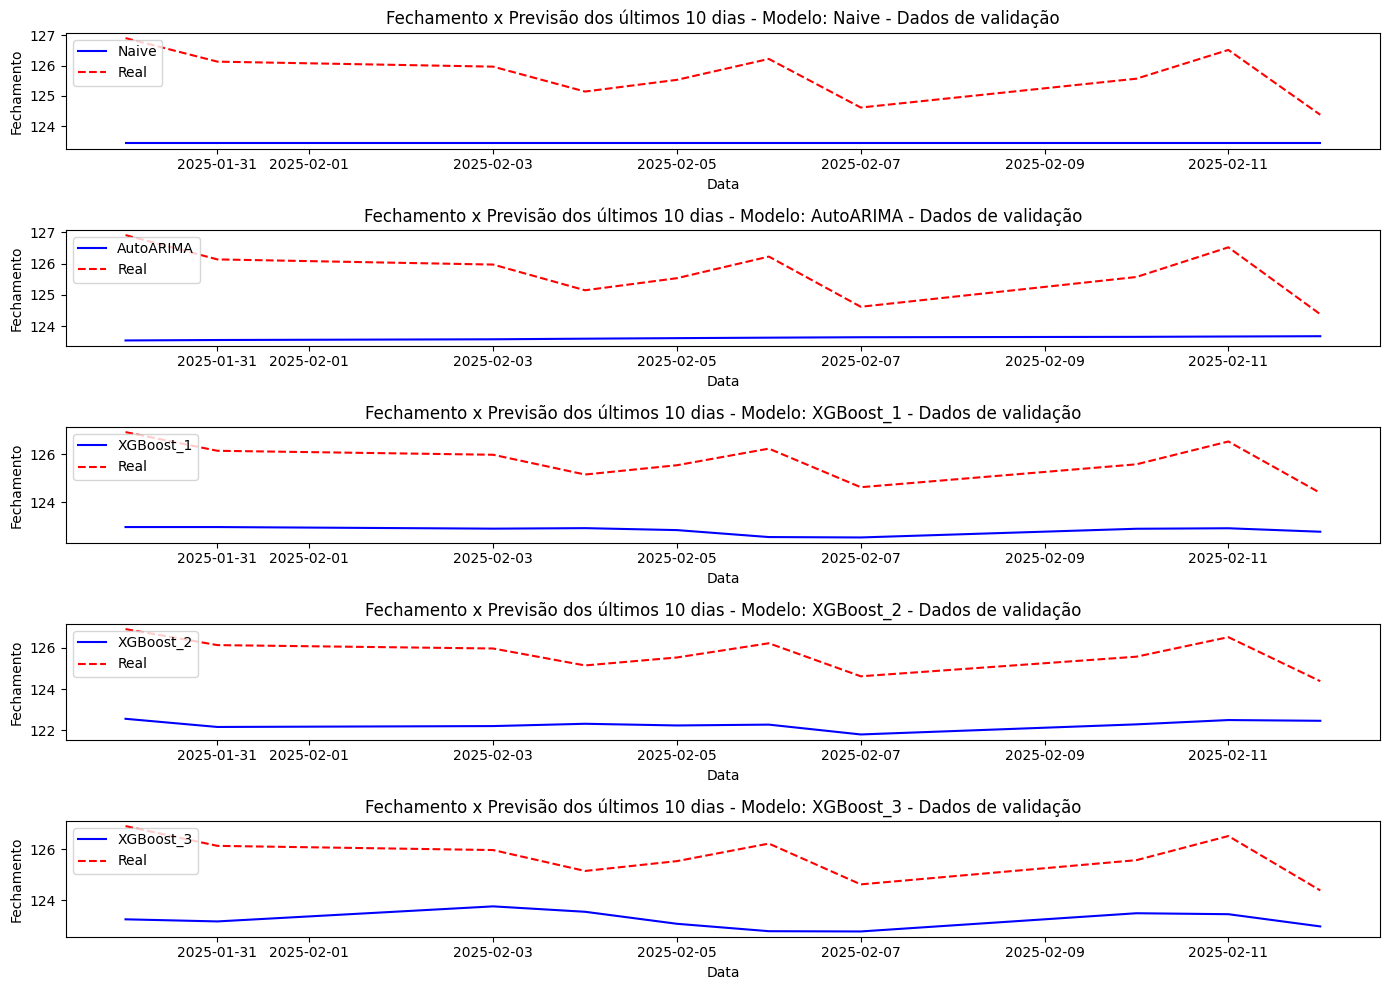

In [56]:
plota_graficos_e_erros(resultado_validacao, 'validação')

Diminuir o max_dephts para 5 diminuiu o erro do modelo

In [57]:
## Treinando e testando o modelo XGBOOST
# Quarta Iteração
reg = xgb.XGBRegressor(objective='reg:squarederror',
                       n_estimators=1200,
                       early_stopping_rounds=50,
                       learning_rate = 0.01,
                       max_depth=4 # Diminuindo a profundidade da árvore de decisão para 4
                       )

resultado_validacao['XGBoost_4'] = treina_e_testa_modelo_xgb(reg, X_train_val, X_val, y_train_val, y_val)

[0]	validation_0-rmse:26.82730	validation_1-rmse:33.04386
[100]	validation_0-rmse:11.18280	validation_1-rmse:13.22398
[200]	validation_0-rmse:6.27717	validation_1-rmse:5.73221
[300]	validation_0-rmse:4.83326	validation_1-rmse:3.26562
[400]	validation_0-rmse:4.22032	validation_1-rmse:2.47756
[448]	validation_0-rmse:4.00639	validation_1-rmse:2.50941
            importance
dayofweek     0.000078
dayofmonth    0.000460
month         0.023855
dayofyear     0.032662
quarter       0.105842
year          0.837103


      Modelo     WMAPE       MAE        MSE  MAPE (%)
0      Naive  0.018056  2.269700   5.746086  1.801923
1  AutoARIMA  0.016594  2.085902   4.984245  1.655583
2  XGBoost_1  0.022925  2.881770   8.821457  2.289184
3  XGBoost_2  0.027269  3.427699  12.242892  2.723634
4  XGBoost_3  0.019750  2.482612   6.709853  1.971782
5  XGBoost_4  0.018652  2.344568   6.091548  1.861485


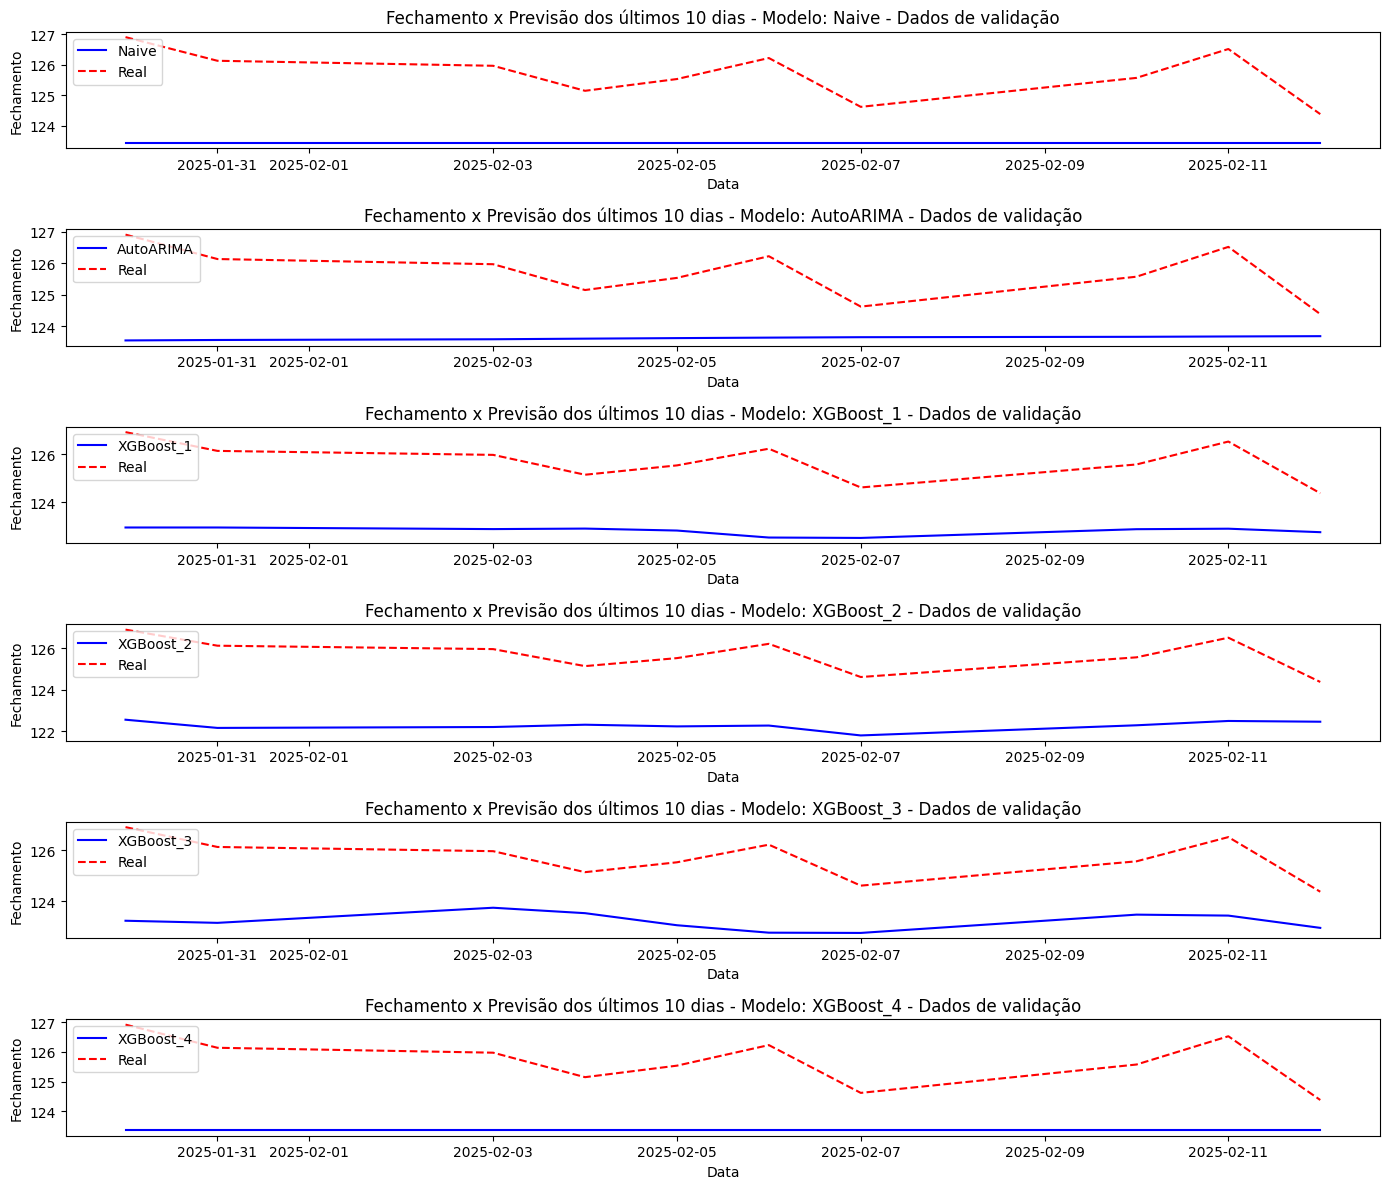

In [58]:
plota_graficos_e_erros(resultado_validacao, 'validação')

Diminuir o max_depths para 4 diminuiu o erro do modelo mas o modelo apresentou um valor constante igual ao modelo Naive. Por este motivo iremos continuar com max_depths = 5

In [59]:
## Treinando e testando o modelo XGBOOST
# Quinta Iteração
reg = xgb.XGBRegressor(objective='reg:squarederror',
                       n_estimators=1200,
                       early_stopping_rounds=50,
                       learning_rate = 0.01,
                       max_depth=5,
                       booster= 'gblinear' # Alterando o modelo para regressão linear (gblinear)
                       )

resultado_validacao['XGBoost_5'] = treina_e_testa_modelo_xgb(reg, X_train_val, X_val, y_train_val, y_val)

[0]	validation_0-rmse:27.08192	validation_1-rmse:33.31483
[60]	validation_0-rmse:27.06719	validation_1-rmse:33.50528
            importance
dayofweek    -0.531577
dayofmonth   -0.065726
year         -0.000721
dayofyear     0.017876
month         0.447523
quarter       1.132626


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [21:40:45] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "max_depth" } are not used.

  warnings.warn(smsg, UserWarning)


      Modelo     WMAPE        MAE          MSE   MAPE (%)
0      Naive  0.018056   2.269700     5.746086   1.801923
1  AutoARIMA  0.016594   2.085902     4.984245   1.655583
2  XGBoost_1  0.022925   2.881770     8.821457   2.289184
3  XGBoost_2  0.027269   3.427699    12.242892   2.723634
4  XGBoost_3  0.019750   2.482612     6.709853   1.971782
5  XGBoost_4  0.018652   2.344568     6.091548   1.861485
6  XGBoost_5  0.266468  33.495525  1122.603870  26.643919


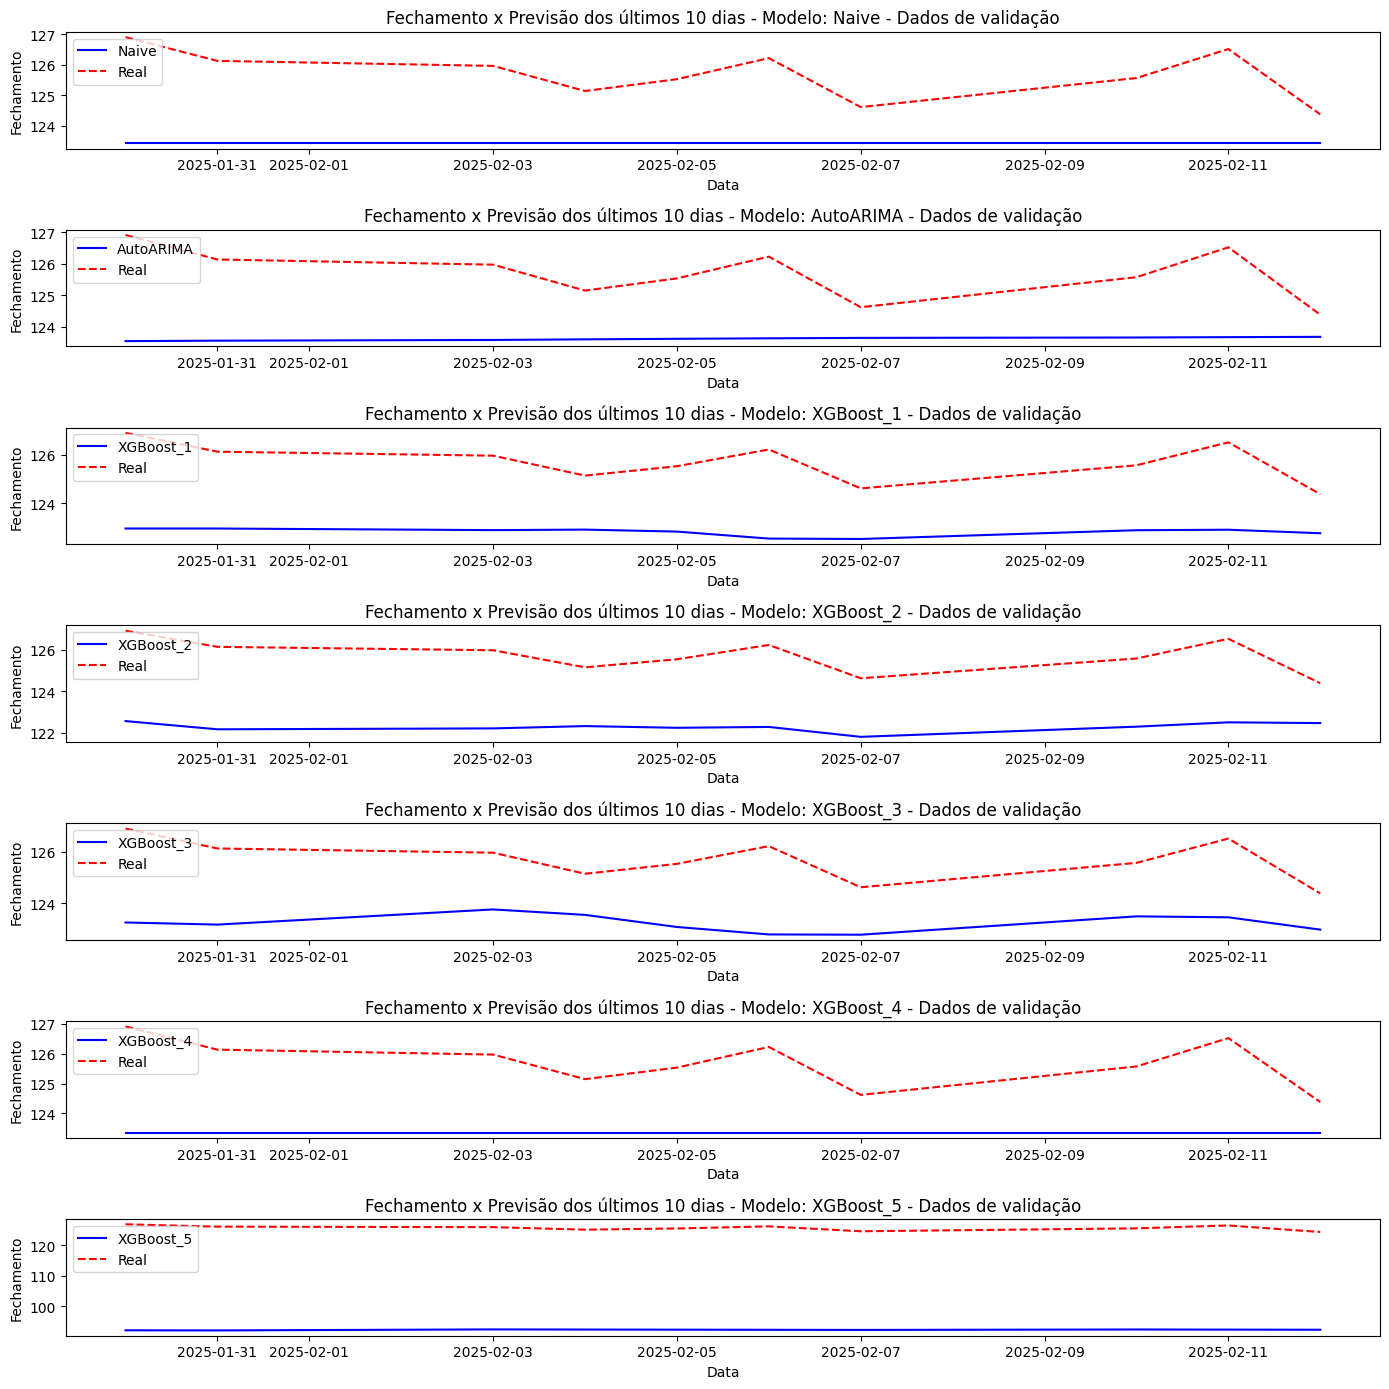

In [60]:
plota_graficos_e_erros(resultado_validacao, 'validação')

Alterar o tipo do modelo para regressão linear aumentou o erro em muito em comparação com as iterações anteriores

In [61]:
## Treinando e testando o modelo XGBOOST
# Sexta Iteração
reg = xgb.XGBRegressor(objective='reg:squarederror',
                       n_estimators=1200,
                       early_stopping_rounds=50,
                       learning_rate = 0.01,
                       max_depth=5,
                       booster = 'dart'  # Alterando o modelo para DART (Dropouts para árvores de decisão, reduz overfitting)
                       )

resultado_validacao['XGBoost_6'] = treina_e_testa_modelo_xgb(reg, X_train_val, X_val, y_train_val, y_val)

[0]	validation_0-rmse:26.82151	validation_1-rmse:33.04386
[100]	validation_0-rmse:10.56744	validation_1-rmse:13.82417
[200]	validation_0-rmse:4.98416	validation_1-rmse:6.51387
[300]	validation_0-rmse:3.26196	validation_1-rmse:4.35586
[400]	validation_0-rmse:2.78290	validation_1-rmse:3.75606
[500]	validation_0-rmse:2.33056	validation_1-rmse:3.38882
[600]	validation_0-rmse:2.05485	validation_1-rmse:3.09803
[700]	validation_0-rmse:1.95745	validation_1-rmse:2.85134
[800]	validation_0-rmse:1.79137	validation_1-rmse:2.79614
[900]	validation_0-rmse:1.68911	validation_1-rmse:2.71531
[1000]	validation_0-rmse:1.57597	validation_1-rmse:2.61087
[1093]	validation_0-rmse:1.52781	validation_1-rmse:2.59514
            importance
dayofweek     0.000167
dayofmonth    0.000684
month         0.014741
quarter       0.024519
dayofyear     0.031636
year          0.928253


      Modelo     WMAPE        MAE          MSE   MAPE (%)
0      Naive  0.018056   2.269700     5.746086   1.801923
1  AutoARIMA  0.016594   2.085902     4.984245   1.655583
2  XGBoost_1  0.022925   2.881770     8.821457   2.289184
3  XGBoost_2  0.027269   3.427699    12.242892   2.723634
4  XGBoost_3  0.019750   2.482612     6.709853   1.971782
5  XGBoost_4  0.018652   2.344568     6.091548   1.861485
6  XGBoost_5  0.266468  33.495525  1122.603870  26.643919
7  XGBoost_6  0.019750   2.482617     6.709878   1.971786


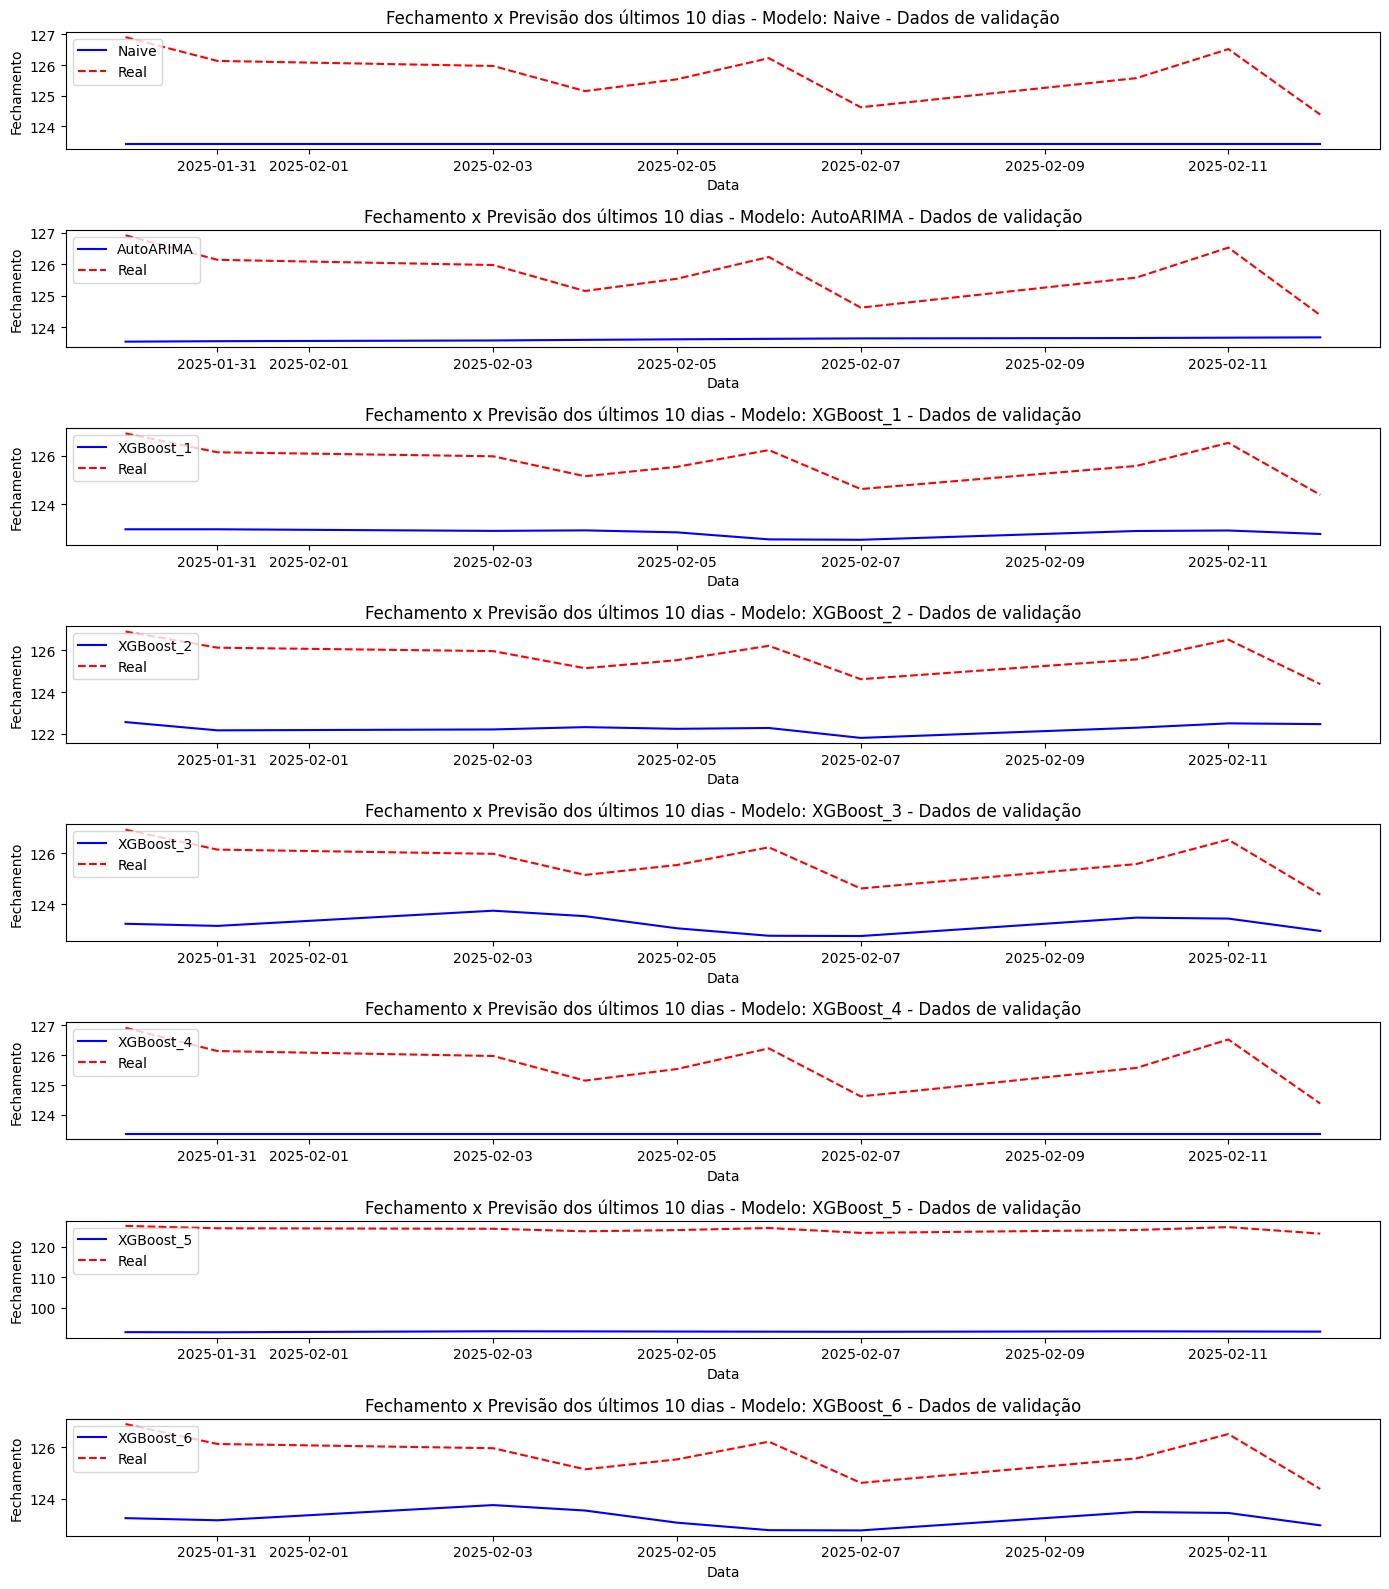

In [62]:
plota_graficos_e_erros(resultado_validacao, 'validação')

Alterar o modelo para DART não aumentou a precisão do modelo mas aumentou o tempo de treinamento. Por este motivo o modelo da terceira iteração (xgboost_3) é o melhor modelo

## Criando um modelo de LSTM (Long Short-Term Memory ou Memória de Longo Curto Prazo)

In [63]:
## Para trabalhar com um modelo de LSTM é necessário transformar o dataframe para um algoritimo supervisionado.
## Dessa forma, as variáveis explicativas serão os dias anteriores (lag) definidos durante o treinamento

# Criando uma função para pegar os valores dos últimos n(lag) dias (variáveis explicativas)
def df_com_janela_temporal(dataframe, start_date, last_date, n=3):
  # Pega a data de inicio como variável alvo para verificar os dias anteriores
  target_date = start_date

  # Criando listas para salvar as datas, variáveis explicativas (x) e variável alvo (y)
  dates = []
  X, Y = [], []

  # Criando um looping para criar as colunas de dias anteriores (lag) para cada dia do dataframe fornecido
  last_time = False
  while True:
    # Cria um dataframe com os dados dos ultimos 4 dias do dia selecionado no loop
    df_subset = dataframe.loc[:target_date].tail(n+1)

    # Verifica se o número de dias do dataframe fornecido é menor que o numero de dias anteriores (lag) fornecido
    if len(df_subset) != n+1:
      print(f'A quantidade de {n} é maior que a {target_date}')
      return

    # Transforma os valores do dataframe em uma array
    values = df_subset['y'].to_numpy()

    x = values[:-1]  # Pega os valores dos dias anteriores
    y = values[-1]   # Pega o valor do dia atual

    dates.append(target_date) # Adiciona o dia atual do loop na lista
    X.append(x) # Adiciona o array de dias anterios a lista
    Y.append(y) # Adiciona o array do dia atual a lista

    next_week = dataframe.loc[target_date:target_date+datetime.timedelta(days=7)] # Verifica o mesmo dia na próxima semana
    next_datetime_str = str(next_week.head(2).tail(1).index.values[0]) # Transforma o dia da próxima semana de datetime para tipo string
    next_date_str = next_datetime_str.split('T')[0] # Separa a data do tempo e seleciona apenas a data
    year, month, day = next_date_str.split('-') # Separa o ano, mês e dia da data
    next_date = datetime.datetime(day=int(day), month=int(month), year=int(year)) # Seleciona a proxima data da próxima semana

    # Se for útimo dia, quebra o loop
    if last_time:
      break

    # Passa a data do próximo dia para o dia inicial
    target_date = next_date

    # Verifica se é o último dia do dataframe fornecido
    if target_date == last_date:
      last_time = True

  # Cria um dataframe com os dados transformados
  df_final = pd.DataFrame({})

  # Adiciona a coluna data
  df_final['data'] = dates

  # Para cada dia anterior escolhido n(lag) cria uma coluna com o nome lag-n
  X = np.array(X)
  for i in range(0, n):
    X[:, i]
    df_final[f'lag-{n-i}'] = X[:, i]

  # Adiciona a coluna com a variável explicativa (fechamento)
  df_final['target'] = Y

  return df_final

In [64]:
## Criando uma função para separar o dataframe em variáveis explicativas (x) e variável alvo (y)
def split_x_y(dataframe):
  df_np = dataframe.to_numpy()

  data = df_np[:, 0]
  x = df_np[:, 1:-1].reshape(len(data),df_np[:, 1:-1].shape[1],1)
  y = df_np[:, -1]

  return data, x.astype(np.float32), y.astype(np.float32)

In [65]:
## Testando com lag de 3 dias
lag = 3

## Criando um dataframe com o numero de lags definido
df_lstm = df_com_janela_temporal(df, df.index[lag], df.index[-1], lag)
df_lstm.head()

,data,lag-3,lag-2,lag-1,target
0,2015-01-07,48.512,47.517,48.001,49.463
1,2015-01-08,47.517,48.001,49.463,49.943
2,2015-01-09,48.001,49.463,49.943,48.840
3,2015-01-12,49.463,49.943,48.840,48.140
4,2015-01-13,49.943,48.840,48.140,48.042


In [66]:
## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_lstm) - (total_de_dias * 2)
tamanho_treino_teste = len(df_lstm) - total_de_dias

## Criando os dataframes com os dados de validação
data_treino_validacao, x_treino_validacao, y_treino_validacao = split_x_y(df_lstm.iloc[:tamanho_treino_validacao])
data_validacao, x_validacao, y_validacao = split_x_y(df_lstm.iloc[tamanho_treino_validacao:tamanho_treino_teste])
print(f'Total de dados para treinamento com dados de validação: {len(y_treino_validacao)}')
print(f'Total de dados para teste: {len(y_validacao)}')

## Criando os dataframes com os dados de teste
data_treino_teste, x_treino_teste, y_treino_teste = split_x_y(df_lstm.iloc[:tamanho_treino_teste])
data_teste, x_teste, y_teste = split_x_y(df_lstm.iloc[tamanho_treino_teste:])
print(f'Total de dados para treinamento com dados de teste: {len(y_treino_teste)}')
print(f'Total de dados para teste: {len(y_teste)}')

Total de dados para treinamento com dados de validação: 2626
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2636
Total de dados para teste: 10


In [67]:
## Modelo LSTM
## Primeira iteração
model = Sequential([layers.Input((lag, 1)),
                    layers.LSTM(64),
                    layers.Dense(32, activation='relu'),
                    layers.Dense(1)
                    ])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mean_absolute_error'
              ])

model.fit(x_treino_validacao, y_treino_validacao, validation_data=(x_validacao, y_validacao), epochs=100)

Epoch 1/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 9137.6475 - mean_absolute_error: 91.6588 - val_loss: 12880.7031 - val_mean_absolute_error: 113.4906
Epoch 2/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5894.4980 - mean_absolute_error: 71.3455 - val_loss: 5606.4966 - val_mean_absolute_error: 74.8726
Epoch 3/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1873.2174 - mean_absolute_error: 36.7316 - val_loss: 1880.1107 - val_mean_absolute_error: 43.3533
Epoch 4/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 499.5260 - mean_absolute_error: 17.8328 - val_loss: 528.5416 - val_mean_absolute_error: 22.9769
Epoch 5/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 98.3873 - mean_absolute_error: 6.2791 - val_loss: 165.5169 - val_mean_absolute_error: 12.8405
Epoch 6/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 32.0390 - mean_absolute_error: 3.3966 - val_loss: 59.9558 - val_mean_absolute_error: 7.6971
Epoch 7/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 14.3161 -

In [68]:
## Testando os valores:
y_pred = model.predict(x_validacao).flatten()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step


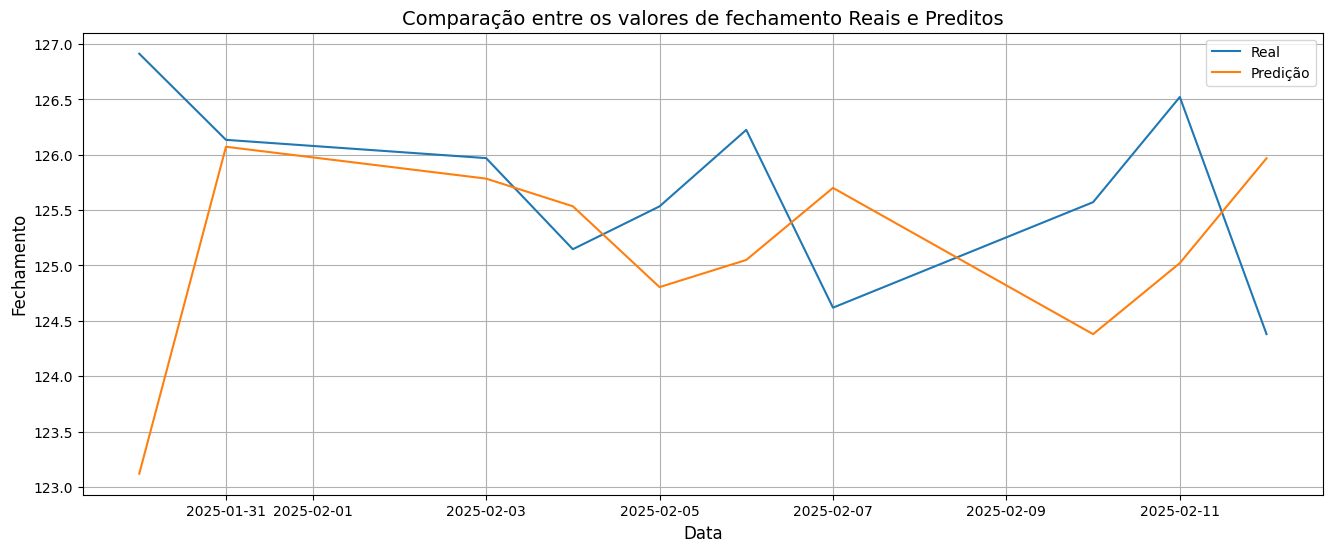

In [69]:
## Plotando o gráfico com os valores preditos
plt.figure(figsize=(16, 6))

plt.plot(data_validacao, y_validacao, label='Real')
plt.plot(data_validacao, y_pred, label='Predição')

plt.title('Comparação entre os valores de fechamento Reais e Preditos', fontsize=14)  # Título do gráfico
plt.xlabel('Data', fontsize=12)  # Rótulo do eixo X
plt.ylabel('Fechamento', fontsize=12)  # Rótulo do eixo Y

plt.legend()
plt.grid(True)  # Adiciona uma grade para melhor visualização
plt.show()


O modelo faz previsões com base nos últimos n dias de dados. Quando fornecemos essas informações corretamente, ele consegue gerar boas previsões. No entanto, para realizar uma previsão realmente sequencial, precisamos seguir uma abordagem recursiva.

Isso significa que, após prever um novo dia, esse valor precisa ser adicionado ao conjunto de dados para que o modelo possa utilizá-lo na previsão do dia seguinte. Como os dados futuros não existem no momento da previsão, criamos um novo dataframe onde, a cada iteração, o valor recém-previsto é incorporado aos dados históricos.

Dessa forma, conseguimos simular uma previsão contínua e realista, onde o modelo utiliza suas próprias previsões para gerar novos valores, garantindo que cada etapa considere as informações mais recentes disponíveis.


In [70]:
# Cria uma lista para armazenar as previsões
previsoes_lstm = []

# Seleciona os valores da última linha do dataframe de treino
ultimos_lags = deepcopy(x_treino_validacao[-1])

# Fazendo a previsão e adicionando esse valor a lag-1 na próxima previsão
for data in data_validacao:
  previsao = model.predict(np.array([ultimos_lags])).flatten()
  previsoes_lstm.append(previsao)
  ultimos_lags[-1] = previsao

resultado_validacao['LSTM_1'] = [arr[0] for arr in previsoes_lstm]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


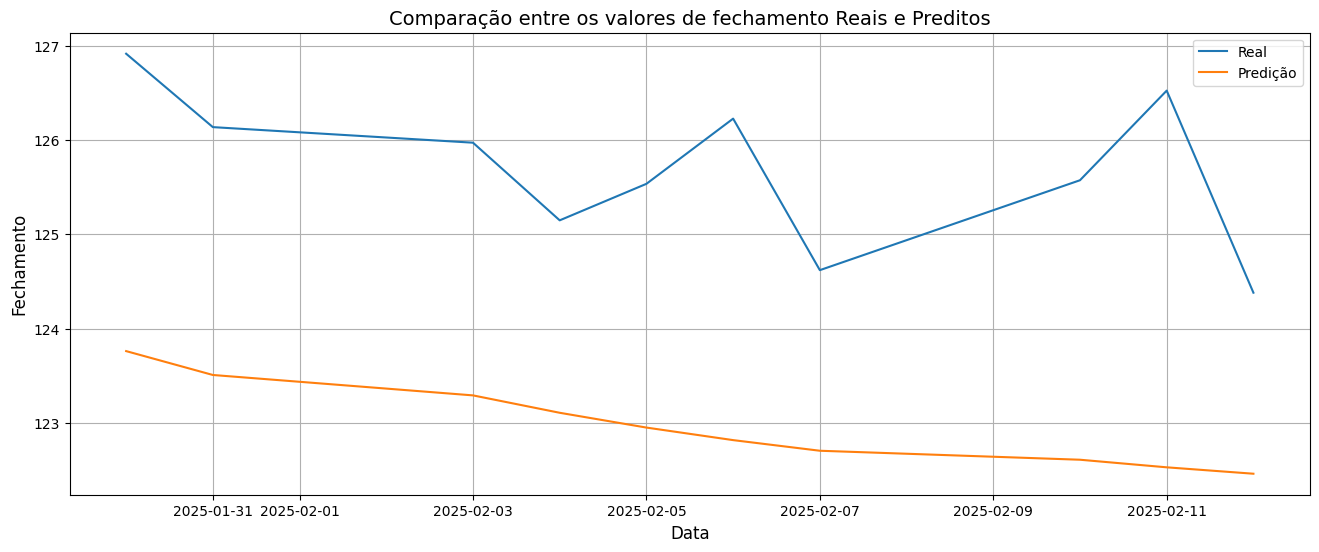

In [71]:
## Plotando o gráfico com os valores preditos
plt.figure(figsize=(16, 6))

plt.plot(data_validacao, y_validacao, label='Real')
plt.plot(data_validacao, previsoes_lstm, label='Predição')

plt.title('Comparação entre os valores de fechamento Reais e Preditos', fontsize=14)  # Título do gráfico
plt.xlabel('Data', fontsize=12)  # Rótulo do eixo X
plt.ylabel('Fechamento', fontsize=12)  # Rótulo do eixo Y

plt.legend()
plt.grid(True)  # Adiciona uma grade para melhor visualização
plt.show()


      Modelo     WMAPE        MAE          MSE   MAPE (%)
0      Naive  0.018056   2.269700     5.746086   1.801923
1  AutoARIMA  0.016594   2.085902     4.984245   1.655583
2  XGBoost_1  0.022925   2.881770     8.821457   2.289184
3  XGBoost_2  0.027269   3.427699    12.242892   2.723634
4  XGBoost_3  0.019750   2.482612     6.709853   1.971782
5  XGBoost_4  0.018652   2.344568     6.091548   1.861485
6  XGBoost_5  0.266468  33.495525  1122.603870  26.643919
7  XGBoost_6  0.019750   2.482617     6.709878   1.971786
8     LSTM_1  0.021700   2.727670     7.852267   2.167388


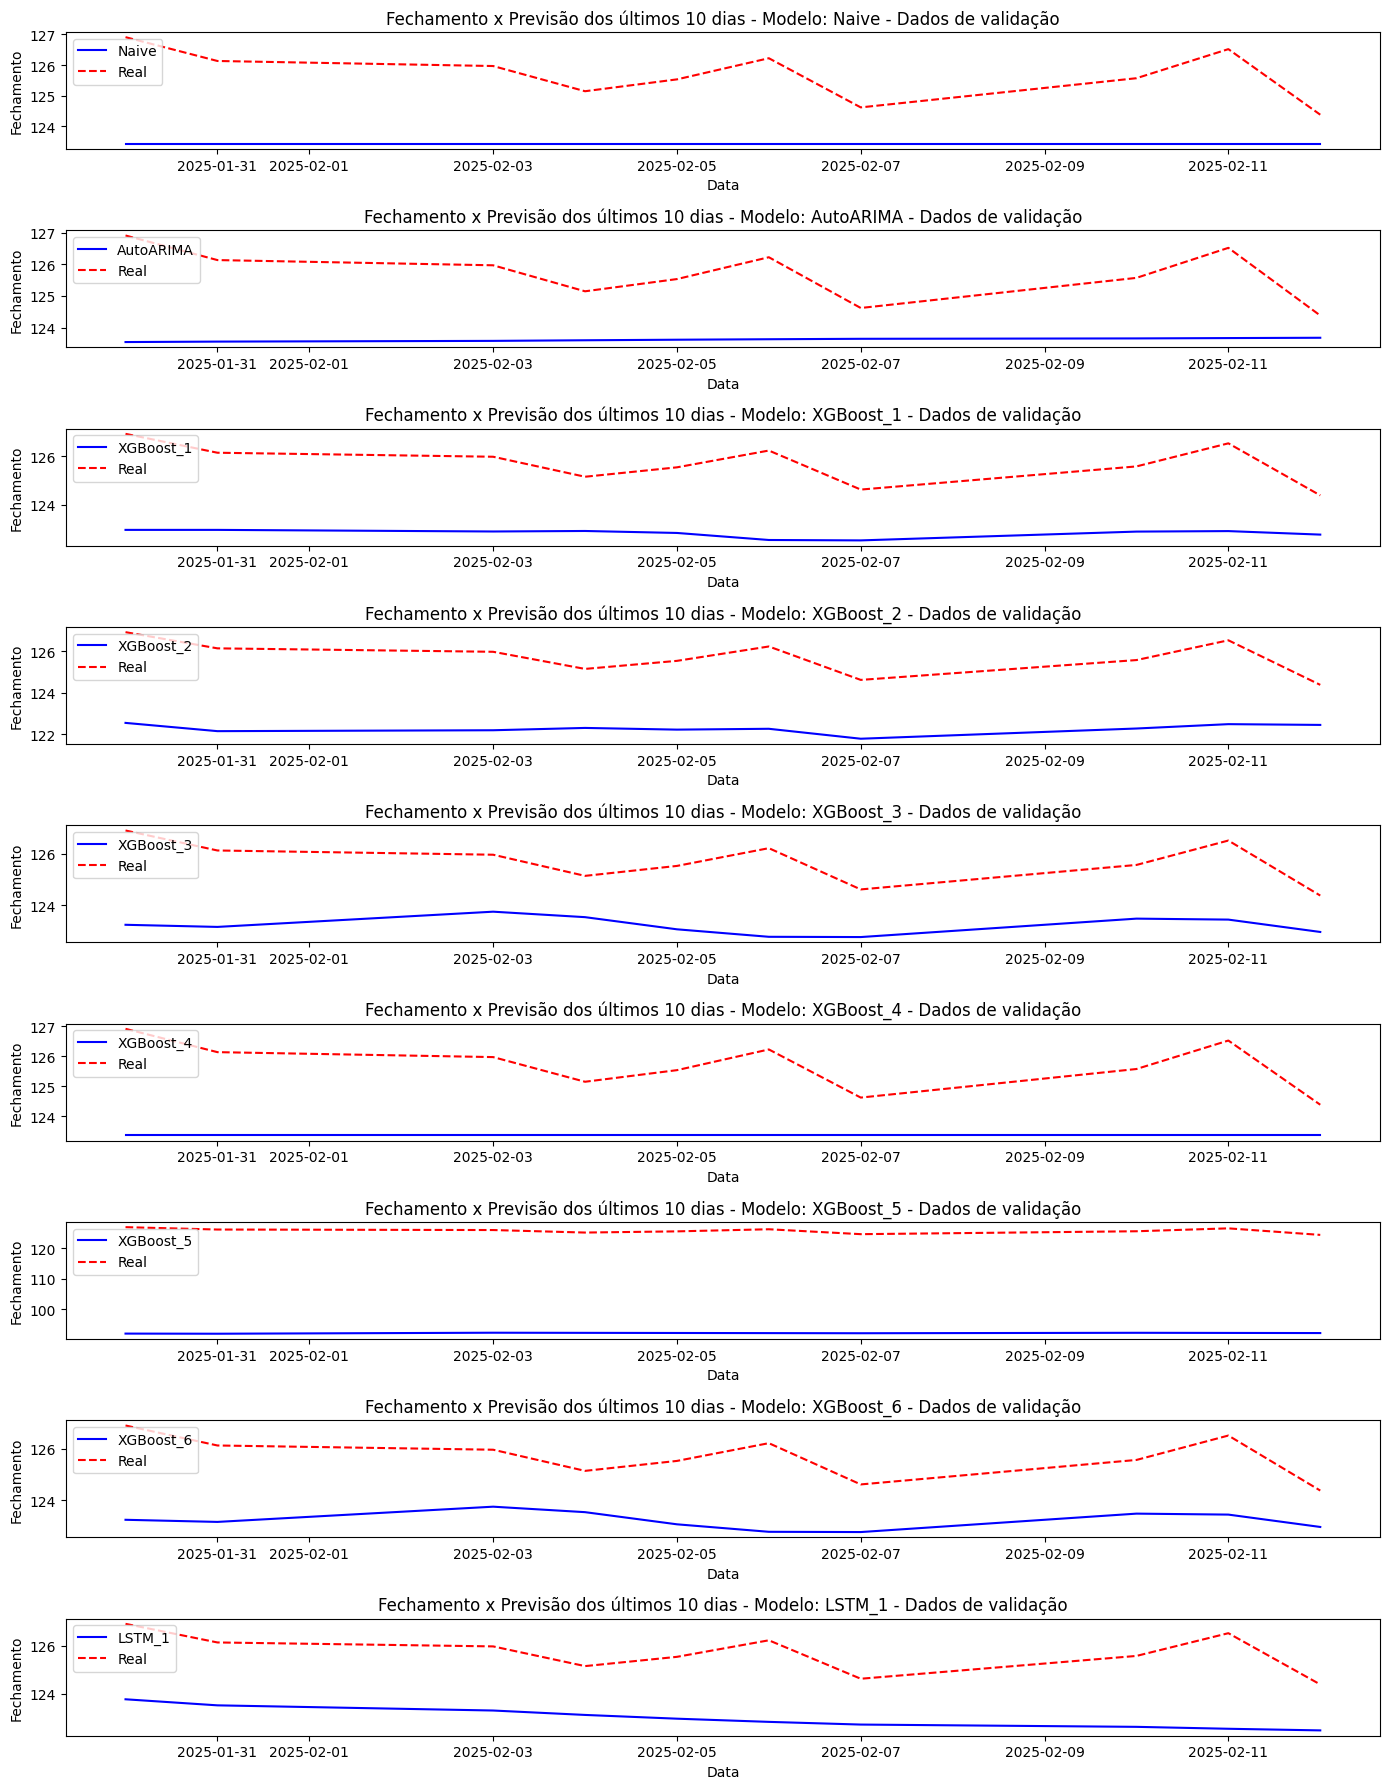

In [72]:
## Avaliando com outros modelos
plota_graficos_e_erros(resultado_validacao, 'validação')

Iremos realizar testes com diferentes lags para tentar aumentar a precisão


In [73]:
## Segunda Interação
## Testando com lag de 1 semana (5 dias úteis)
lag = 5

## Criando um dataframe com o numero de lags definido
df_lstm = df_com_janela_temporal(df, df.index[lag], df.index[-1], lag)
df_lstm.head()

## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_lstm) - (total_de_dias * 2)
tamanho_treino_teste = len(df_lstm) - total_de_dias

## Criando os dataframes com os dados de validação
data_treino_validacao, x_treino_validacao, y_treino_validacao = split_x_y(df_lstm.iloc[:tamanho_treino_validacao])
data_validacao, x_validacao, y_validacao = split_x_y(df_lstm.iloc[tamanho_treino_validacao:tamanho_treino_teste])
print(f'Total de dados para treinamento com dados de validação: {len(y_treino_validacao)}')
print(f'Total de dados para teste: {len(y_validacao)}')

## Criando os dataframes com os dados de teste
data_treino_teste, x_treino_teste, y_treino_teste = split_x_y(df_lstm.iloc[:tamanho_treino_teste])
data_teste, x_teste, y_teste = split_x_y(df_lstm.iloc[tamanho_treino_teste:])
print(f'Total de dados para treinamento com dados de teste: {len(y_treino_teste)}')
print(f'Total de dados para teste: {len(y_teste)}')

## Treinando o modelo
model = Sequential([layers.Input((lag, 1)),
                    layers.LSTM(64),
                    layers.Dense(32, activation='relu'),
                    layers.Dense(1)
                    ])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mean_absolute_error'
              ])

model.fit(x_treino_validacao, y_treino_validacao, validation_data=(x_validacao, y_validacao), epochs=100)

# Cria uma lista para armazenar as previsões
previsoes_lstm = []

# Seleciona os valores da última linha do dataframe de treino
ultimos_lags = deepcopy(x_treino_validacao[-1])

# Fazendo a previsão e adicionando esse valor a lag-1 na próxima previsão
for data in data_validacao:
  previsao = model.predict(np.array([ultimos_lags])).flatten()
  previsoes_lstm.append(previsao)
  ultimos_lags[-1] = previsao

resultado_validacao['LSTM_2'] = [arr[0] for arr in previsoes_lstm]

Total de dados para treinamento com dados de validação: 2624
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2634
Total de dados para teste: 10
Epoch 1/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 8519.9707 - mean_absolute_error: 88.1057 - val_loss: 9791.6240 - val_mean_absolute_error: 98.9497
Epoch 2/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3399.2249 - mean_absolute_error: 50.9561 - val_loss: 1915.2070 - val_mean_absolute_error: 43.7563
Epoch 3/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 605.6052 - mean_absolute_error: 21.2065 - val_loss: 430.6107 - val_mean_absolute_error: 20.7365
Epoch 4/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 66.6023 - mean_absolute_error: 4.9362 - val_loss: 67.7472 - val_mean_absolute_error: 8.1921
Epoch 5/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 14.7881 - mean_absolute_error: 2.2755 - val_loss: 13.7139 - val_mean_absolute_error: 3.5986
Epoch 6/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step 

      Modelo     WMAPE        MAE          MSE   MAPE (%)
0      Naive  0.018056   2.269700     5.746086   1.801923
1  AutoARIMA  0.016594   2.085902     4.984245   1.655583
2  XGBoost_1  0.022925   2.881770     8.821457   2.289184
3  XGBoost_2  0.027269   3.427699    12.242892   2.723634
4  XGBoost_3  0.019750   2.482612     6.709853   1.971782
5  XGBoost_4  0.018652   2.344568     6.091548   1.861485
6  XGBoost_5  0.266468  33.495525  1122.603870  26.643919
7  XGBoost_6  0.019750   2.482617     6.709878   1.971786
8     LSTM_1  0.021700   2.727670     7.852267   2.167388
9     LSTM_2  0.023642   2.971815     9.245552   2.361838


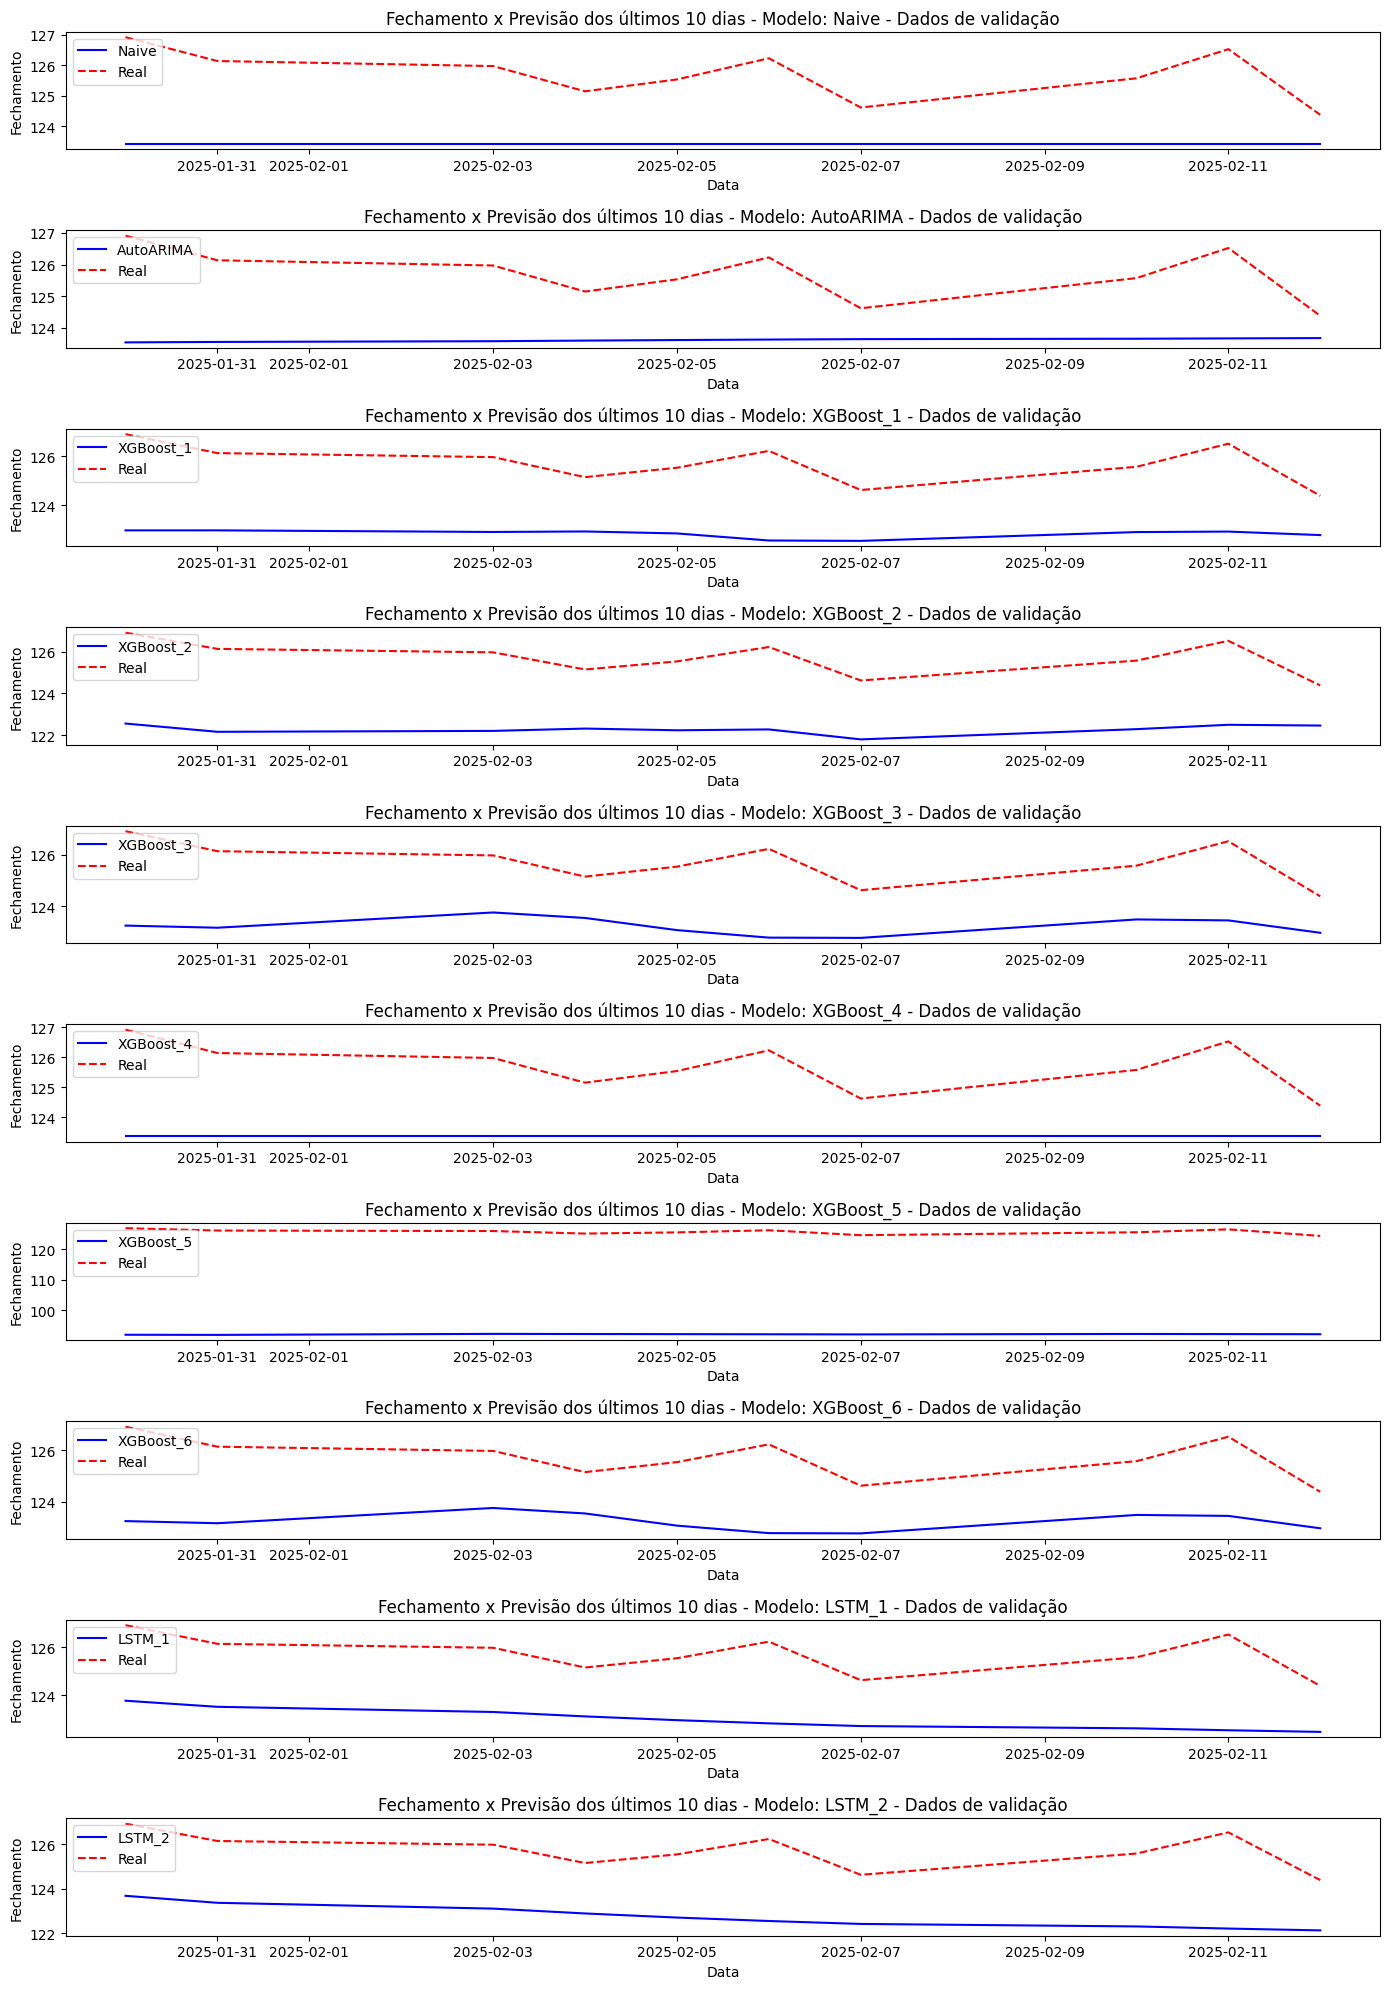

In [74]:
## Avaliando com outros modelos
plota_graficos_e_erros(resultado_validacao, 'validação')

In [75]:
## Terceira Interação
## Testando com lag de 2 semanas (10 dias úteis)
lag = 10

## Criando um dataframe com o numero de lags definido
df_lstm = df_com_janela_temporal(df, df.index[lag], df.index[-1], lag)
df_lstm.head()

## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_lstm) - (total_de_dias * 2)
tamanho_treino_teste = len(df_lstm) - total_de_dias

## Criando os dataframes com os dados de validação
data_treino_validacao, x_treino_validacao, y_treino_validacao = split_x_y(df_lstm.iloc[:tamanho_treino_validacao])
data_validacao, x_validacao, y_validacao = split_x_y(df_lstm.iloc[tamanho_treino_validacao:tamanho_treino_teste])
print(f'Total de dados para treinamento com dados de validação: {len(y_treino_validacao)}')
print(f'Total de dados para teste: {len(y_validacao)}')

## Criando os dataframes com os dados de teste
data_treino_teste, x_treino_teste, y_treino_teste = split_x_y(df_lstm.iloc[:tamanho_treino_teste])
data_teste, x_teste, y_teste = split_x_y(df_lstm.iloc[tamanho_treino_teste:])
print(f'Total de dados para treinamento com dados de teste: {len(y_treino_teste)}')
print(f'Total de dados para teste: {len(y_teste)}')

## Treinando o modelo
model = Sequential([layers.Input((lag, 1)),
                    layers.LSTM(64),
                    layers.Dense(32, activation='relu'),
                    layers.Dense(1)
                    ])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mean_absolute_error'
              ])

model.fit(x_treino_validacao, y_treino_validacao, validation_data=(x_validacao, y_validacao), epochs=100)

# Cria uma lista para armazenar as previsões
previsoes_lstm = []

# Seleciona os valores da última linha do dataframe de treino
ultimos_lags = deepcopy(x_treino_validacao[-1])

# Fazendo a previsão e adicionando esse valor a lag-1 na próxima previsão
for data in data_validacao:
  previsao = model.predict(np.array([ultimos_lags])).flatten()
  previsoes_lstm.append(previsao)
  ultimos_lags[-1] = previsao

resultado_validacao['LSTM_3'] = [arr[0] for arr in previsoes_lstm]

Total de dados para treinamento com dados de validação: 2619
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2629
Total de dados para teste: 10
Epoch 1/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 9021.7617 - mean_absolute_error: 91.0654 - val_loss: 13178.3418 - val_mean_absolute_error: 114.7944
Epoch 2/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6087.8066 - mean_absolute_error: 72.7155 - val_loss: 5946.9531 - val_mean_absolute_error: 77.1126
Epoch 3/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2007.6234 - mean_absolute_error: 38.1368 - val_loss: 2296.2512 - val_mean_absolute_error: 47.9130
Epoch 4/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 744.1949 - mean_absolute_error: 23.6594 - val_loss: 923.5459 - val_mean_absolute_error: 30.3797
Epoch 5/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 187.5772 - mean_absolute_error: 9.6754 - val_loss: 275.0528 - val_mean_absolute_error: 16.5658
Epoch 6/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 

       Modelo     WMAPE        MAE          MSE   MAPE (%)
0       Naive  0.018056   2.269700     5.746086   1.801923
1   AutoARIMA  0.016594   2.085902     4.984245   1.655583
2   XGBoost_1  0.022925   2.881770     8.821457   2.289184
3   XGBoost_2  0.027269   3.427699    12.242892   2.723634
4   XGBoost_3  0.019750   2.482612     6.709853   1.971782
5   XGBoost_4  0.018652   2.344568     6.091548   1.861485
6   XGBoost_5  0.266468  33.495525  1122.603870  26.643919
7   XGBoost_6  0.019750   2.482617     6.709878   1.971786
8      LSTM_1  0.021700   2.727670     7.852267   2.167388
9      LSTM_2  0.023642   2.971815     9.245552   2.361838
10     LSTM_3  0.001944   1.049060     1.777546   0.835923


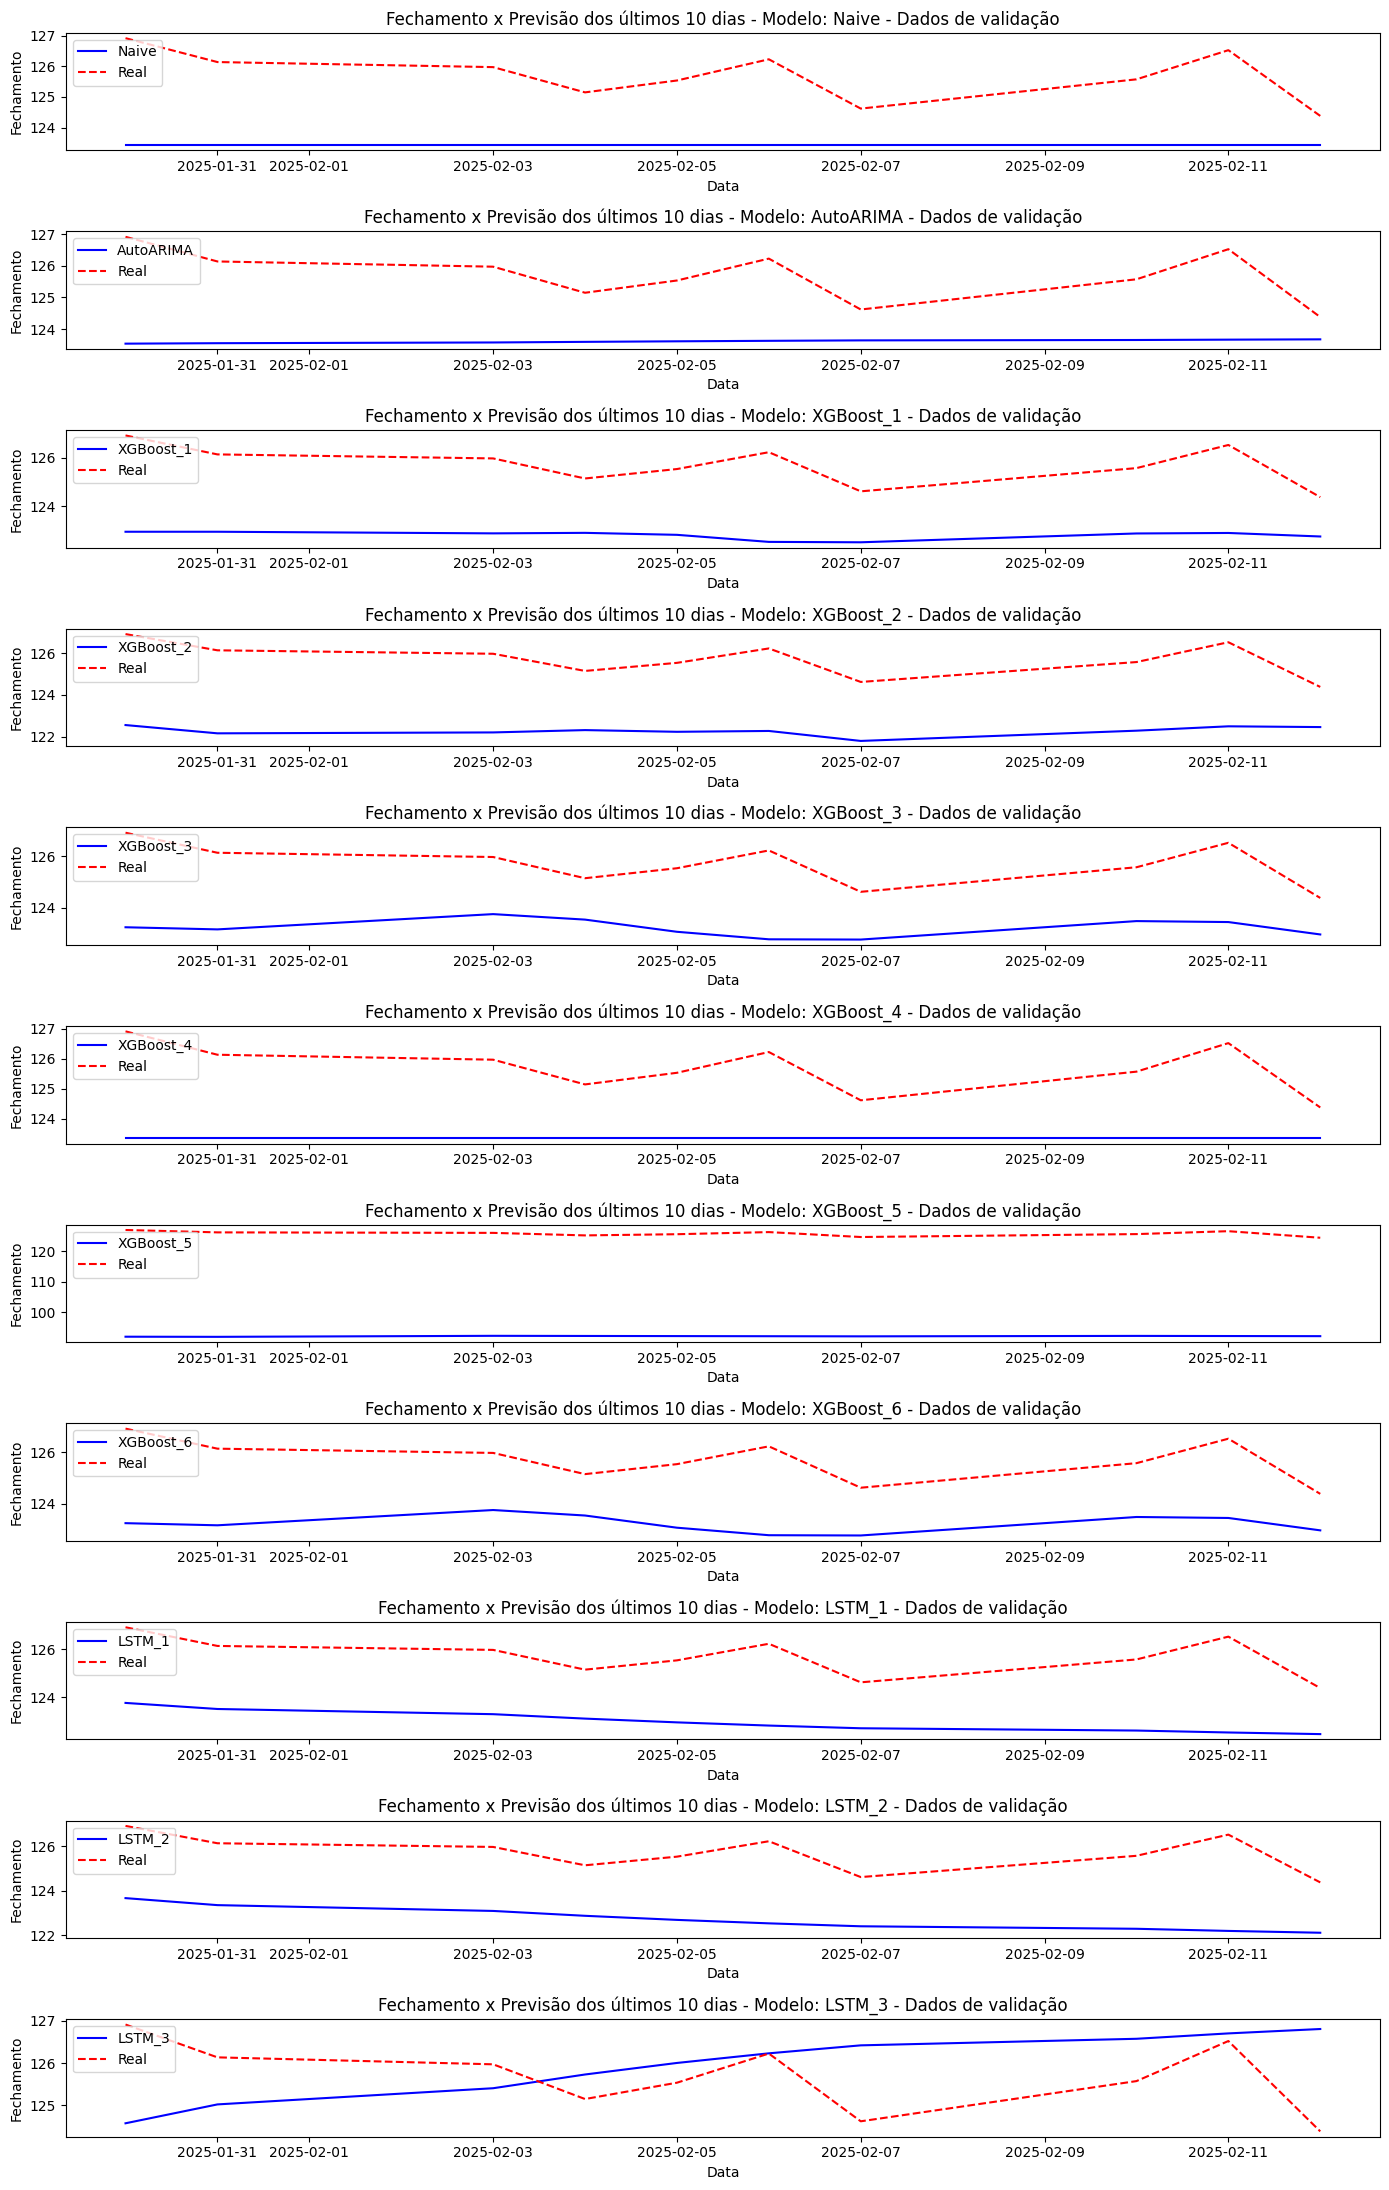

In [76]:
## Avaliando com outros modelos
plota_graficos_e_erros(resultado_validacao, 'validação')

In [77]:
## Quarta Interação
## Testando com lag de 3 semanas (15 dias úteis)
lag = 15

## Criando um dataframe com o numero de lags definido
df_lstm = df_com_janela_temporal(df, df.index[lag], df.index[-1], lag)
df_lstm.head()

## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_lstm) - (total_de_dias * 2)
tamanho_treino_teste = len(df_lstm) - total_de_dias

## Criando os dataframes com os dados de validação
data_treino_validacao, x_treino_validacao, y_treino_validacao = split_x_y(df_lstm.iloc[:tamanho_treino_validacao])
data_validacao, x_validacao, y_validacao = split_x_y(df_lstm.iloc[tamanho_treino_validacao:tamanho_treino_teste])
print(f'Total de dados para treinamento com dados de validação: {len(y_treino_validacao)}')
print(f'Total de dados para teste: {len(y_validacao)}')

## Criando os dataframes com os dados de teste
data_treino_teste, x_treino_teste, y_treino_teste = split_x_y(df_lstm.iloc[:tamanho_treino_teste])
data_teste, x_teste, y_teste = split_x_y(df_lstm.iloc[tamanho_treino_teste:])
print(f'Total de dados para treinamento com dados de teste: {len(y_treino_teste)}')
print(f'Total de dados para teste: {len(y_teste)}')

## Treinando o modelo
model = Sequential([layers.Input((lag, 1)),
                    layers.LSTM(64),
                    layers.Dense(32, activation='relu'),
                    layers.Dense(1)
                    ])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mean_absolute_error'
              ])

model.fit(x_treino_validacao, y_treino_validacao, validation_data=(x_validacao, y_validacao), epochs=100)

# Cria uma lista para armazenar as previsões
previsoes_lstm = []

# Seleciona os valores da última linha do dataframe de treino
ultimos_lags = deepcopy(x_treino_validacao[-1])

# Fazendo a previsão e adicionando esse valor a lag-1 na próxima previsão
for data in data_validacao:
  previsao = model.predict(np.array([ultimos_lags])).flatten()
  previsoes_lstm.append(previsao)
  ultimos_lags[-1] = previsao

resultado_validacao['LSTM_4'] = [arr[0] for arr in previsoes_lstm]

Total de dados para treinamento com dados de validação: 2614
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2624
Total de dados para teste: 10
Epoch 1/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 8804.0107 - mean_absolute_error: 89.7135 - val_loss: 10337.4951 - val_mean_absolute_error: 101.6706
Epoch 2/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 4052.1460 - mean_absolute_error: 56.8198 - val_loss: 2787.4707 - val_mean_absolute_error: 52.7909
Epoch 3/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 873.5877 - mean_absolute_error: 25.8231 - val_loss: 797.1751 - val_mean_absolute_error: 28.2231
Epoch 4/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 165.9403 - mean_absolute_error: 9.5140 - val_loss: 147.7664 - val_mean_absolute_error: 12.1296
Epoch 5/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 28.0764 - mean_absolute_error: 3.2192 - val_loss: 31.1395 - val_mean_absolute_error: 5.5209
Epoch 6/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9m

       Modelo     WMAPE        MAE          MSE   MAPE (%)
0       Naive  0.018056   2.269700     5.746086   1.801923
1   AutoARIMA  0.016594   2.085902     4.984245   1.655583
2   XGBoost_1  0.022925   2.881770     8.821457   2.289184
3   XGBoost_2  0.027269   3.427699    12.242892   2.723634
4   XGBoost_3  0.019750   2.482612     6.709853   1.971782
5   XGBoost_4  0.018652   2.344568     6.091548   1.861485
6   XGBoost_5  0.266468  33.495525  1122.603870  26.643919
7   XGBoost_6  0.019750   2.482617     6.709878   1.971786
8      LSTM_1  0.021700   2.727670     7.852267   2.167388
9      LSTM_2  0.023642   2.971815     9.245552   2.361838
10     LSTM_3  0.001944   1.049060     1.777546   0.835923
11     LSTM_4  0.001301   0.951201     1.506860   0.756629


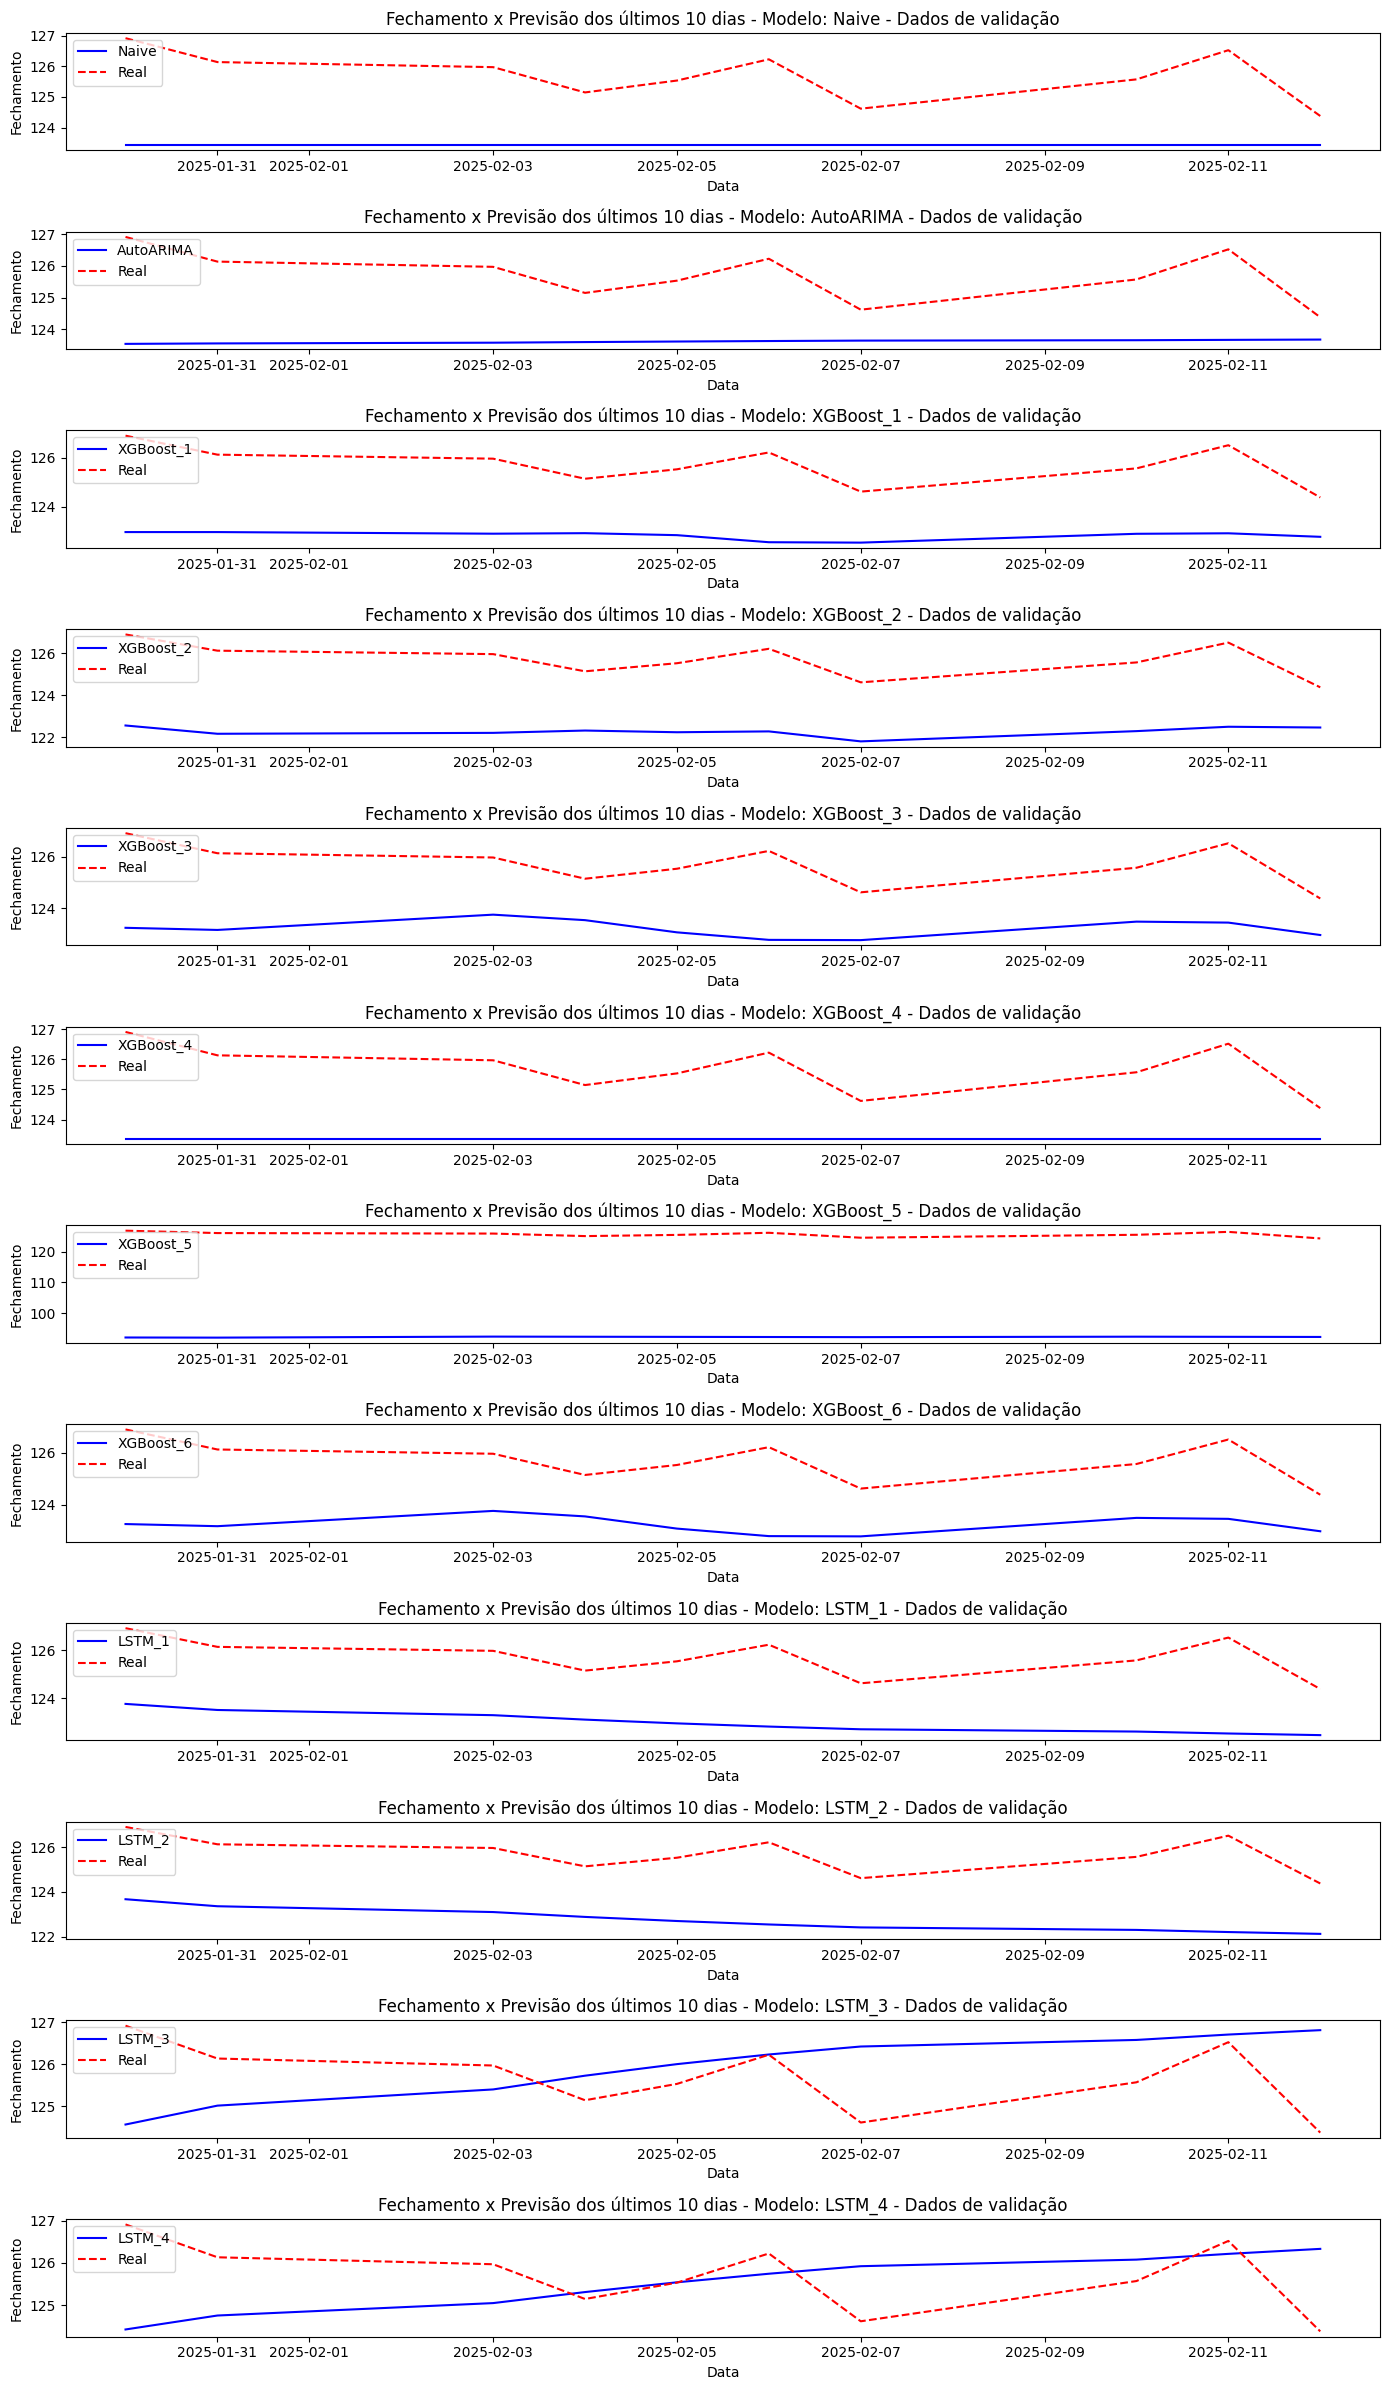

In [78]:
## Avaliando com outros modelos
plota_graficos_e_erros(resultado_validacao, 'validação')

In [79]:
## Quinta Interação
## Testando com lag de 1 mes (22 dias úteis)
lag = 22

## Criando um dataframe com o numero de lags definido
df_lstm = df_com_janela_temporal(df, df.index[lag], df.index[-1], lag)
df_lstm.head()

## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_lstm) - (total_de_dias * 2)
tamanho_treino_teste = len(df_lstm) - total_de_dias

## Criando os dataframes com os dados de validação
data_treino_validacao, x_treino_validacao, y_treino_validacao = split_x_y(df_lstm.iloc[:tamanho_treino_validacao])
data_validacao, x_validacao, y_validacao = split_x_y(df_lstm.iloc[tamanho_treino_validacao:tamanho_treino_teste])
print(f'Total de dados para treinamento com dados de validação: {len(y_treino_validacao)}')
print(f'Total de dados para teste: {len(y_validacao)}')

## Criando os dataframes com os dados de teste
data_treino_teste, x_treino_teste, y_treino_teste = split_x_y(df_lstm.iloc[:tamanho_treino_teste])
data_teste, x_teste, y_teste = split_x_y(df_lstm.iloc[tamanho_treino_teste:])
print(f'Total de dados para treinamento com dados de teste: {len(y_treino_teste)}')
print(f'Total de dados para teste: {len(y_teste)}')

## Treinando o modelo
model = Sequential([layers.Input((lag, 1)),
                    layers.LSTM(64),
                    layers.Dense(32, activation='relu'),
                    layers.Dense(1)
                    ])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mean_absolute_error'
              ])

model.fit(x_treino_validacao, y_treino_validacao, validation_data=(x_validacao, y_validacao), epochs=100)

# Cria uma lista para armazenar as previsões
previsoes_lstm = []

# Seleciona os valores da última linha do dataframe de treino
ultimos_lags = deepcopy(x_treino_validacao[-1])

# Fazendo a previsão e adicionando esse valor a lag-1 na próxima previsão
for data in data_validacao:
  previsao = model.predict(np.array([ultimos_lags])).flatten()
  previsoes_lstm.append(previsao)
  ultimos_lags[-1] = previsao

resultado_validacao['LSTM_5'] = [arr[0] for arr in previsoes_lstm]

Total de dados para treinamento com dados de validação: 2607
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2617
Total de dados para teste: 10
Epoch 1/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 8766.7539 - mean_absolute_error: 89.5441 - val_loss: 10373.8418 - val_mean_absolute_error: 101.8493
Epoch 2/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 3908.1431 - mean_absolute_error: 55.5144 - val_loss: 2584.7898 - val_mean_absolute_error: 50.8350
Epoch 3/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 836.3724 - mean_absolute_error: 25.2009 - val_loss: 822.7848 - val_mean_absolute_error: 28.6729
Epoch 4/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 193.9971 - mean_absolute_error: 10.6378 - val_loss: 184.5206 - val_mean_absolute_error: 13.5594
Epoch 5/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 38.9577 - mean_absolute_error: 4.0336 - val_loss: 40.0466 - val_mean_absolute_error: 6.2756
Epoch 6/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1

       Modelo     WMAPE        MAE          MSE   MAPE (%)
0       Naive  0.018056   2.269700     5.746086   1.801923
1   AutoARIMA  0.016594   2.085902     4.984245   1.655583
2   XGBoost_1  0.022925   2.881770     8.821457   2.289184
3   XGBoost_2  0.027269   3.427699    12.242892   2.723634
4   XGBoost_3  0.019750   2.482612     6.709853   1.971782
5   XGBoost_4  0.018652   2.344568     6.091548   1.861485
6   XGBoost_5  0.266468  33.495525  1122.603870  26.643919
7   XGBoost_6  0.019750   2.482617     6.709878   1.971786
8      LSTM_1  0.021700   2.727670     7.852267   2.167388
9      LSTM_2  0.023642   2.971815     9.245552   2.361838
10     LSTM_3  0.001944   1.049060     1.777546   0.835923
11     LSTM_4  0.001301   0.951201     1.506860   0.756629
12     LSTM_5  0.009148   1.834562     4.671813   1.462606


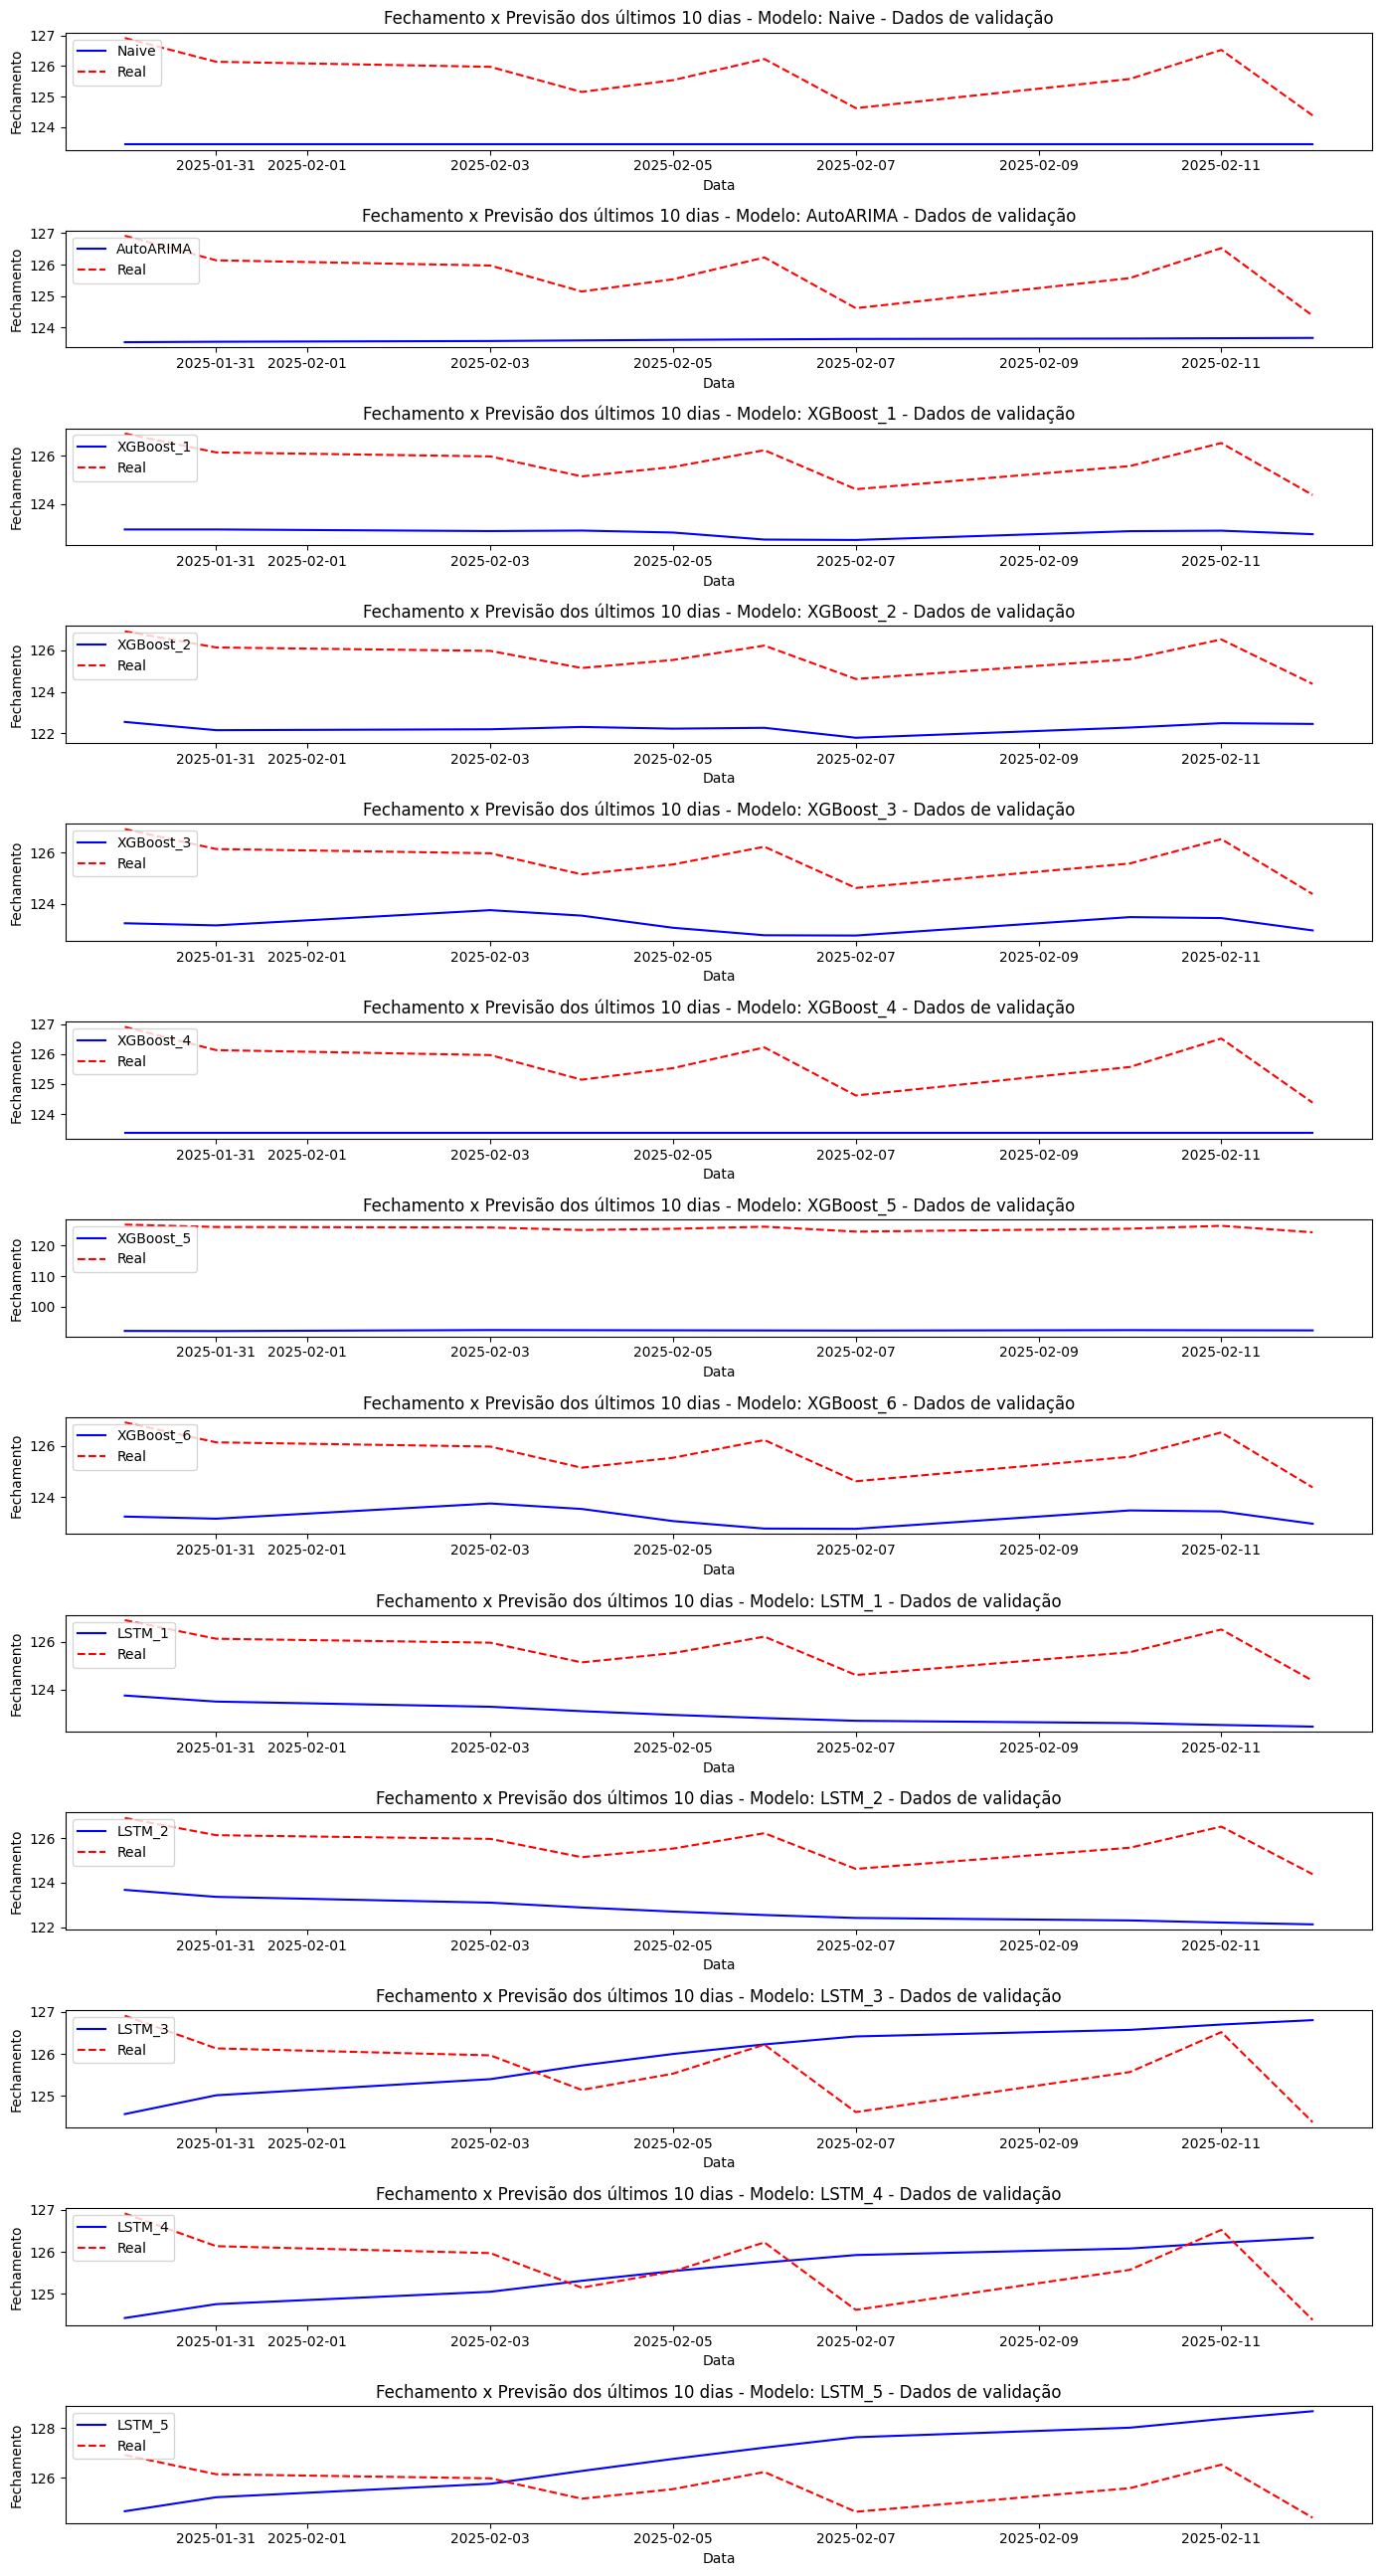

In [80]:
## Avaliando com outros modelos
plota_graficos_e_erros(resultado_validacao, 'validação')

In [81]:
## Quinta Interação
## Testando com lag de 3 meses (65 dias úteis)
lag = 65

## Criando um dataframe com o numero de lags definido
df_lstm = df_com_janela_temporal(df, df.index[lag], df.index[-1], lag)
df_lstm.head()

## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_lstm) - (total_de_dias * 2)
tamanho_treino_teste = len(df_lstm) - total_de_dias

## Criando os dataframes com os dados de validação
data_treino_validacao, x_treino_validacao, y_treino_validacao = split_x_y(df_lstm.iloc[:tamanho_treino_validacao])
data_validacao, x_validacao, y_validacao = split_x_y(df_lstm.iloc[tamanho_treino_validacao:tamanho_treino_teste])
print(f'Total de dados para treinamento com dados de validação: {len(y_treino_validacao)}')
print(f'Total de dados para teste: {len(y_validacao)}')

## Criando os dataframes com os dados de teste
data_treino_teste, x_treino_teste, y_treino_teste = split_x_y(df_lstm.iloc[:tamanho_treino_teste])
data_teste, x_teste, y_teste = split_x_y(df_lstm.iloc[tamanho_treino_teste:])
print(f'Total de dados para treinamento com dados de teste: {len(y_treino_teste)}')
print(f'Total de dados para teste: {len(y_teste)}')

## Treinando o modelo
model = Sequential([layers.Input((lag, 1)),
                    layers.LSTM(64),
                    layers.Dense(32, activation='relu'),
                    layers.Dense(1)
                    ])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mean_absolute_error'
              ])

model.fit(x_treino_validacao, y_treino_validacao, validation_data=(x_validacao, y_validacao), epochs=100)

# Cria uma lista para armazenar as previsões
previsoes_lstm = []

# Seleciona os valores da última linha do dataframe de treino
ultimos_lags = deepcopy(x_treino_validacao[-1])

# Fazendo a previsão e adicionando esse valor a lag-1 na próxima previsão
for data in data_validacao:
  previsao = model.predict(np.array([ultimos_lags])).flatten()
  previsoes_lstm.append(previsao)
  ultimos_lags[-1] = previsao

resultado_validacao['LSTM_6'] = [arr[0] for arr in previsoes_lstm]

Total de dados para treinamento com dados de validação: 2564
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2574
Total de dados para teste: 10
Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 8628.2314 - mean_absolute_error: 88.9066 - val_loss: 8981.9561 - val_mean_absolute_error: 94.7702
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 3160.2717 - mean_absolute_error: 49.2646 - val_loss: 2075.0459 - val_mean_absolute_error: 45.5461
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 604.2194 - mean_absolute_error: 21.1362 - val_loss: 556.2919 - val_mean_absolute_error: 23.5727
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 97.9287 - mean_absolute_error: 6.8034 - val_loss: 114.9111 - val_mean_absolute_error: 10.6902
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 21.7585 - mean_absolute_error: 2.8028 - val_loss: 29.2913 - val_mean_absolute_error: 5.3372
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 25

       Modelo     WMAPE        MAE          MSE   MAPE (%)
0       Naive  0.018056   2.269700     5.746086   1.801923
1   AutoARIMA  0.016594   2.085902     4.984245   1.655583
2   XGBoost_1  0.022925   2.881770     8.821457   2.289184
3   XGBoost_2  0.027269   3.427699    12.242892   2.723634
4   XGBoost_3  0.019750   2.482612     6.709853   1.971782
5   XGBoost_4  0.018652   2.344568     6.091548   1.861485
6   XGBoost_5  0.266468  33.495525  1122.603870  26.643919
7   XGBoost_6  0.019750   2.482617     6.709878   1.971786
8      LSTM_1  0.021700   2.727670     7.852267   2.167388
9      LSTM_2  0.023642   2.971815     9.245552   2.361838
10     LSTM_3  0.001944   1.049060     1.777546   0.835923
11     LSTM_4  0.001301   0.951201     1.506860   0.756629
12     LSTM_5  0.009148   1.834562     4.671813   1.462606
13     LSTM_6  0.025603   3.218311    10.854529   2.558422


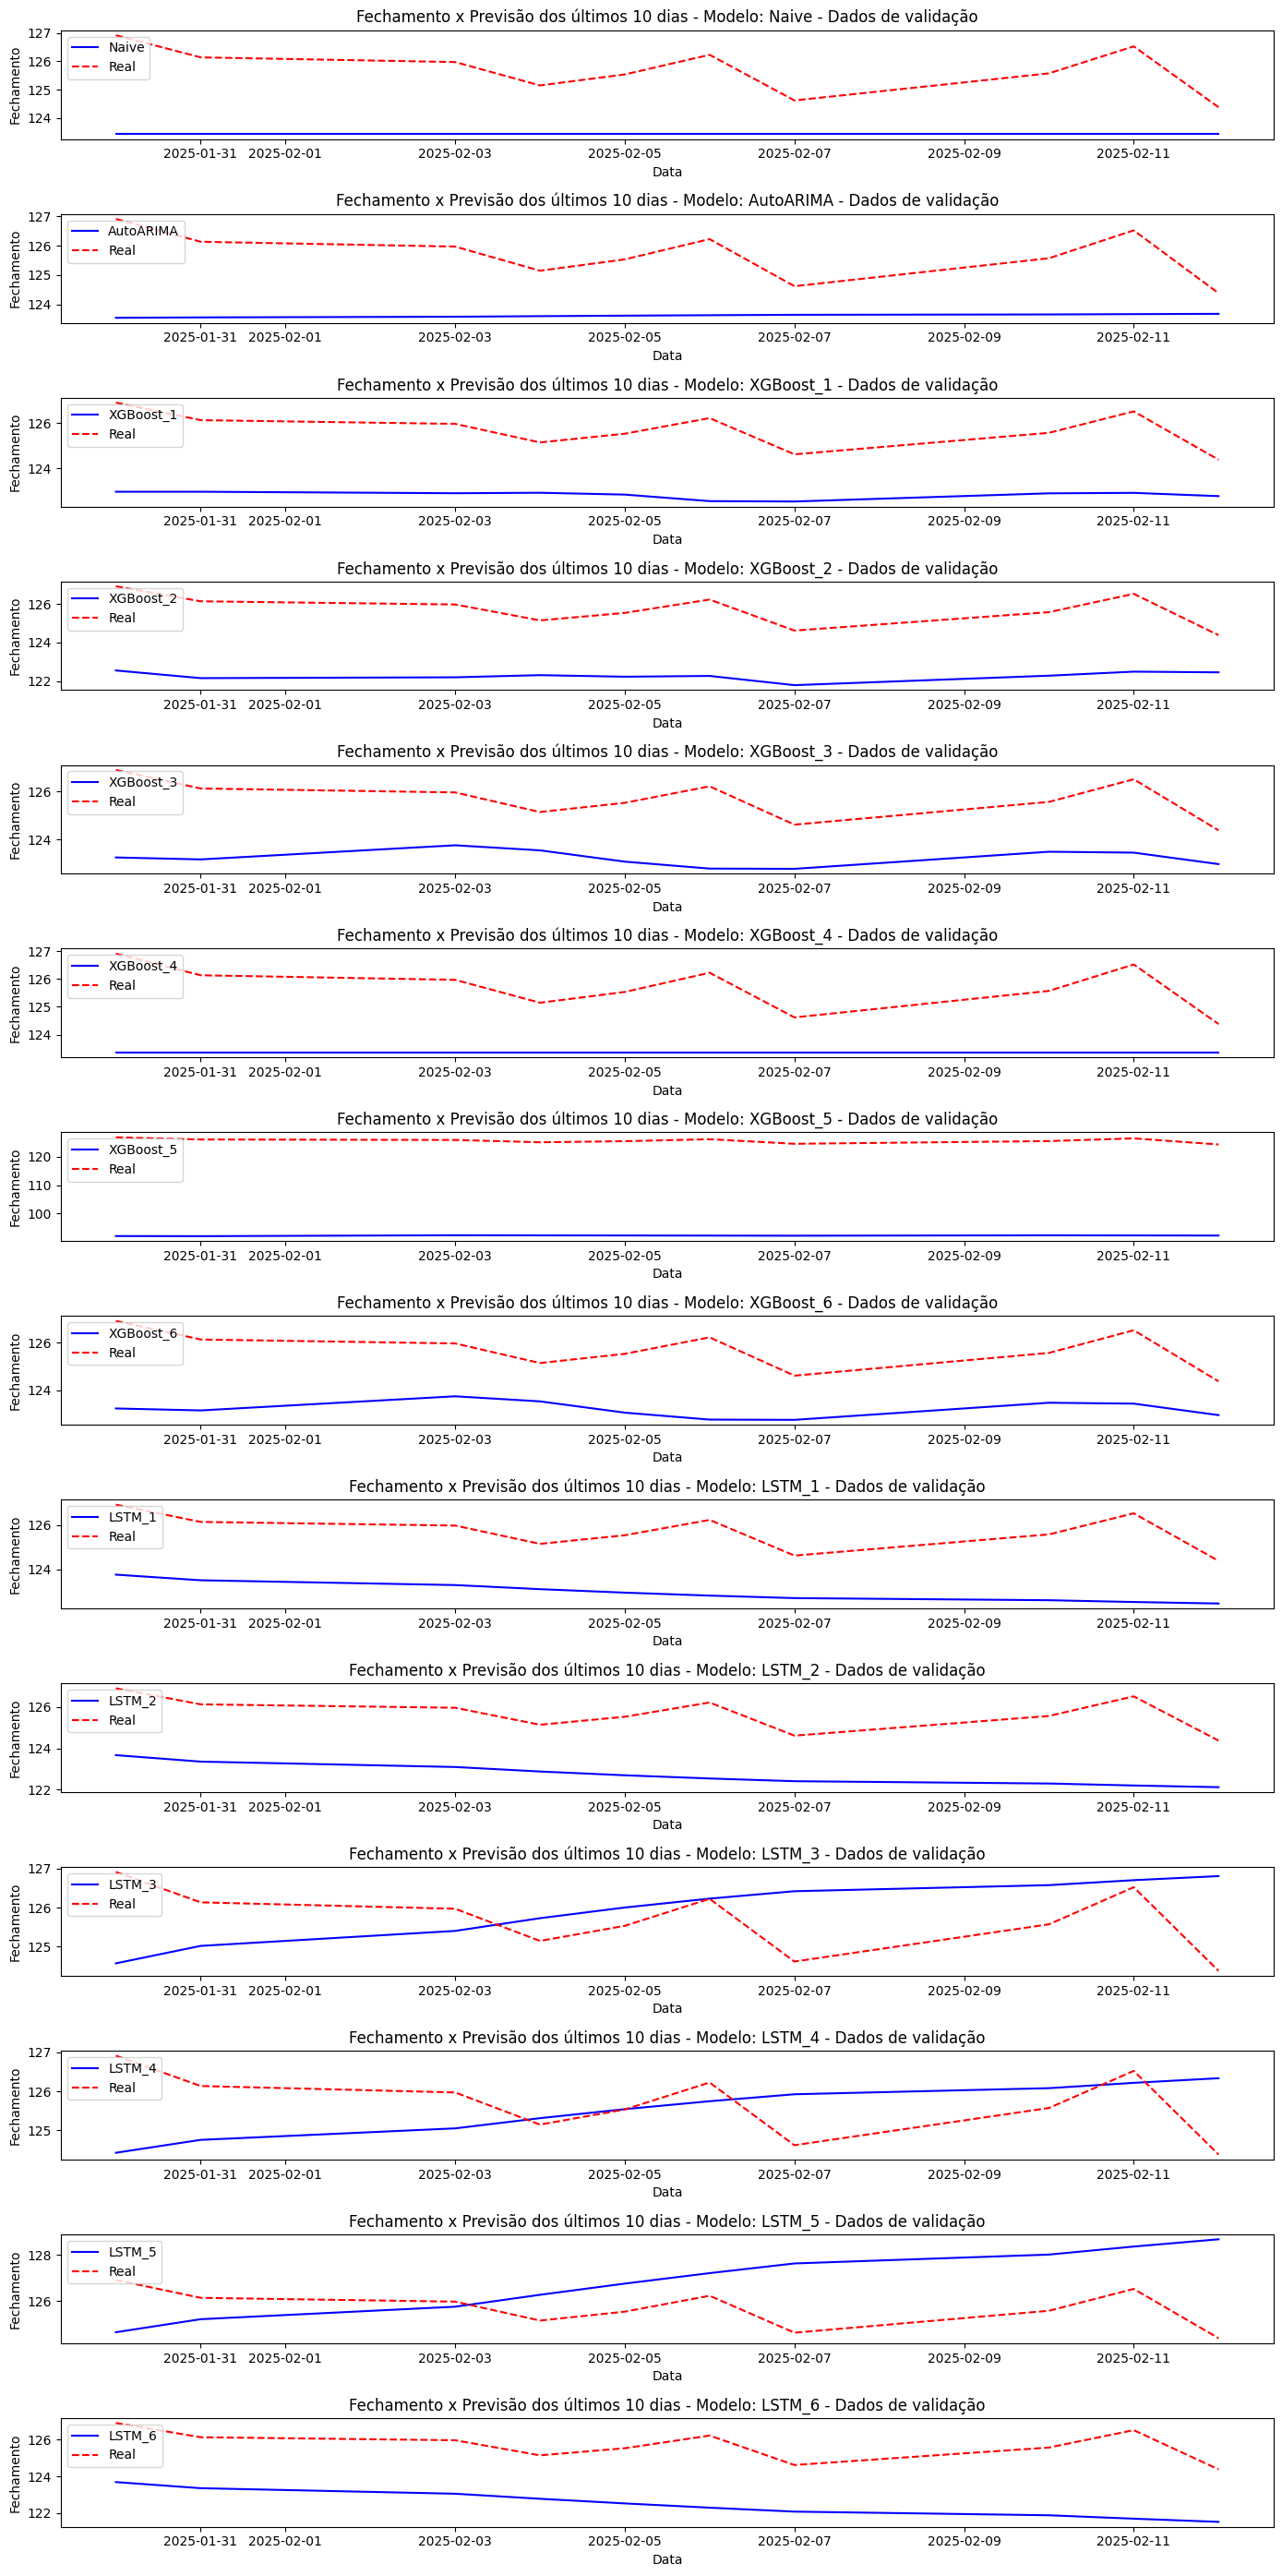

In [82]:
## Avaliando com outros modelos
plota_graficos_e_erros(resultado_validacao, 'validação')

O modelo de LSTM com lag de 3 semanas (15 dias úteis) foi o que apresentou o menor erro e que visualmente apresenta o melhor acompanhamento da tendência de fechamento real

Agora com os modelos já ajustados, iremos testar os melhores modelos com os dados de teste para verificar se houve overfitting ou se o modelo está respondendo bem aos dados

In [83]:
## Testando o melhor modelo XGBoost com os dados de teste
reg = xgb.XGBRegressor(objective='reg:squarederror',
                       n_estimators=1200,
                       early_stopping_rounds=50,
                       learning_rate = 0.01,
                       max_depth=5
                       )

resultado_teste['XGBoost'] = treina_e_testa_modelo_xgb(reg, X_train_test, X_test, y_train_test, y_test)

[0]	validation_0-rmse:26.84730	validation_1-rmse:33.99738
[100]	validation_0-rmse:10.57676	validation_1-rmse:13.97063
[200]	validation_0-rmse:4.98357	validation_1-rmse:6.37012
[300]	validation_0-rmse:3.27088	validation_1-rmse:4.04609
[400]	validation_0-rmse:2.79335	validation_1-rmse:3.09428
[500]	validation_0-rmse:2.41511	validation_1-rmse:2.59381
[600]	validation_0-rmse:2.06050	validation_1-rmse:2.52221
[652]	validation_0-rmse:1.97527	validation_1-rmse:2.54108
            importance
dayofweek     0.000208
dayofmonth    0.000505
month         0.014767
dayofyear     0.026753
quarter       0.063960
year          0.893808


In [84]:
## Testando o melhor modelo LSTM com os dados de teste
lag = 15

## Criando um dataframe com o numero de lags definido
df_lstm = df_com_janela_temporal(df, df.index[lag], df.index[-1], lag)
df_lstm.head()

## Definindo o tamanho dos dataframes de teste e validação
tamanho_treino_validacao = len(df_lstm) - (total_de_dias * 2)
tamanho_treino_teste = len(df_lstm) - total_de_dias

## Criando os dataframes com os dados de validação
data_treino_validacao, x_treino_validacao, y_treino_validacao = split_x_y(df_lstm.iloc[:tamanho_treino_validacao])
data_validacao, x_validacao, y_validacao = split_x_y(df_lstm.iloc[tamanho_treino_validacao:tamanho_treino_teste])
print(f'Total de dados para treinamento com dados de validação: {len(y_treino_validacao)}')
print(f'Total de dados para teste: {len(y_validacao)}')

## Criando os dataframes com os dados de teste
data_treino_teste, x_treino_teste, y_treino_teste = split_x_y(df_lstm.iloc[:tamanho_treino_teste])
data_teste, x_teste, y_teste = split_x_y(df_lstm.iloc[tamanho_treino_teste:])
print(f'Total de dados para treinamento com dados de teste: {len(y_treino_teste)}')
print(f'Total de dados para teste: {len(y_teste)}')

## Treinando o modelo
model = Sequential([layers.Input((lag, 1)),
                    layers.LSTM(64),
                    layers.Dense(32, activation='relu'),
                    layers.Dense(1)
                    ])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mean_absolute_error'
              ])

model.fit(x_treino_teste, y_treino_teste, validation_data=(x_teste, y_teste), epochs=100)

# Cria uma lista para armazenar as previsões
previsoes_lstm = []

# Seleciona os valores da última linha do dataframe de treino
ultimos_lags = deepcopy(x_treino_teste[-1])

# Fazendo a previsão e adicionando esse valor a lag-1 na próxima previsão
for data in data_validacao:
  previsao = model.predict(np.array([ultimos_lags])).flatten()
  previsoes_lstm.append(previsao)
  ultimos_lags[-1] = previsao

resultado_teste['LSTM'] = [arr[0] for arr in previsoes_lstm]

Total de dados para treinamento com dados de validação: 2614
Total de dados para teste: 10
Total de dados para treinamento com dados de teste: 2624
Total de dados para teste: 10
Epoch 1/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 8999.0527 - mean_absolute_error: 90.9061 - val_loss: 12839.0938 - val_mean_absolute_error: 113.3010
Epoch 2/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 5587.4365 - mean_absolute_error: 69.0307 - val_loss: 4936.2998 - val_mean_absolute_error: 70.2448
Epoch 3/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1474.0593 - mean_absolute_error: 32.7374 - val_loss: 1567.0070 - val_mean_absolute_error: 39.5611
Epoch 4/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 378.8533 - mean_absolute_error: 15.8549 - val_loss: 390.5164 - val_mean_absolute_error: 19.7142
Epoch 5/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 60.3138 - mean_absolute_error: 4.8497 - val_loss: 105.8370 - val_mean_absolute_error: 10.1968
Epoch 6/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1

      Modelo     WMAPE       MAE       MSE  MAPE (%)
0      Naive  0.019349  2.454100  7.986266  1.922884
1  AutoARIMA  0.017695  2.244393  7.001887  1.757521
2    XGBoost  0.016550  2.099149  6.296952  1.643227
3       LSTM  0.017313  2.431413  6.659988  1.910082


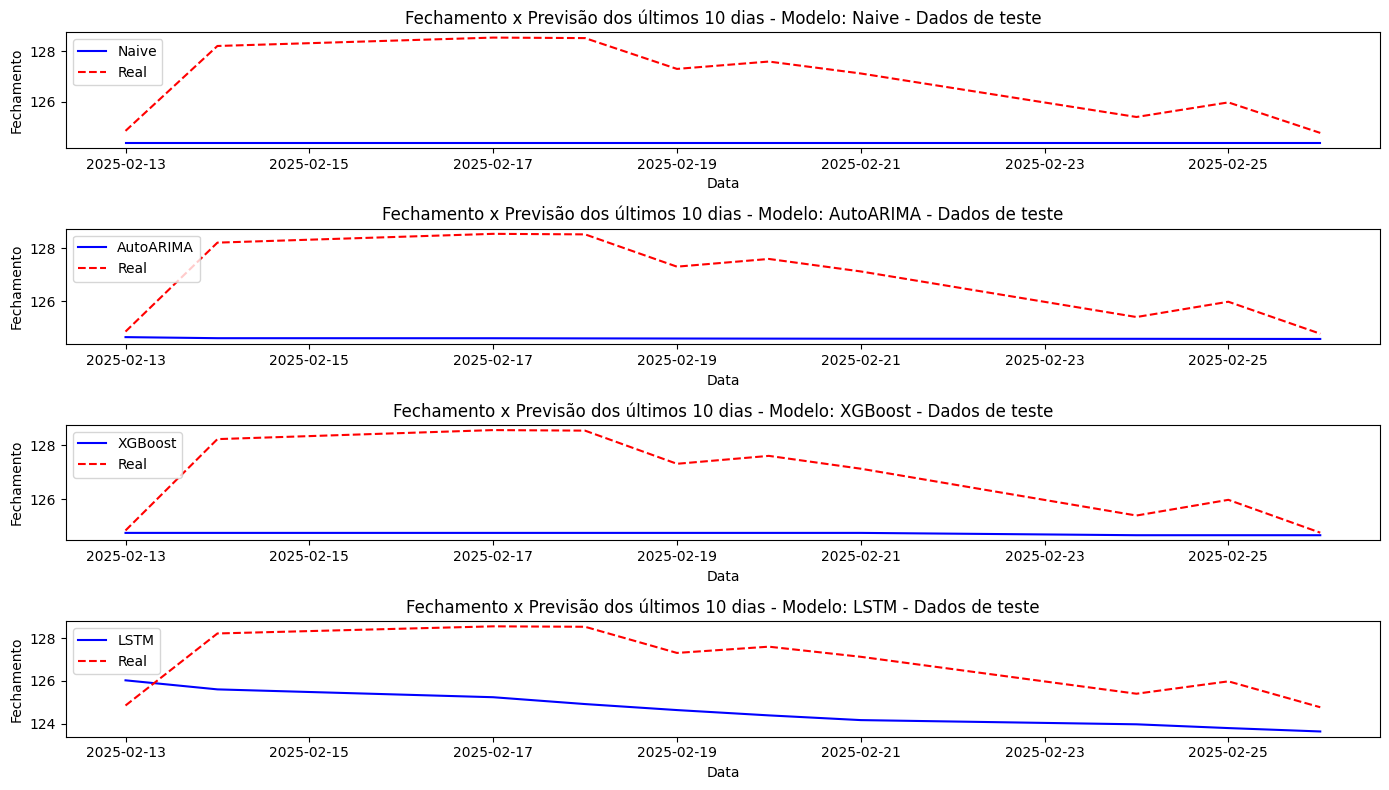

In [85]:
plota_graficos_e_erros(resultado_teste, 'teste')

In [86]:
## Criando uma tabela com os erros e precisão dos modelos
modelos = resultado_teste.columns[2:].tolist()
erros = []

for modelo in modelos:
  wmape_valor = wmape(resultado_teste['y'].values, resultado_teste[modelo].values)
  mae_valor = mean_absolute_error(resultado_teste['y'].values, resultado_teste[modelo].values)
  mse_valor = mean_squared_error(resultado_teste['y'].values, resultado_teste[modelo].values)
  mape_valor = 100 * mean_absolute_percentage_error(resultado_teste['y'].values, resultado_teste[modelo].values)
  rmse_valor = np.sqrt(mean_squared_error(resultado_teste['y'].values, resultado_teste[modelo].values))

  erros.append({
        'Modelo': modelo,
        'WMAPE': wmape_valor,
        'MAE': mae_valor,
        'MSE': mse_valor,
        'RMSE': rmse_valor,
        'MAPE (%)': mape_valor,
        'Accuracy (%)': round(100 - mape_valor, 2)
    })

df_erros = pd.DataFrame(erros)
df_erros = df_erros.sort_values(by='Accuracy (%)', ascending=False)
df_erros

,Modelo,WMAPE,MAE,MSE,RMSE,MAPE (%),Accuracy (%)
2,XGBoost,0.016550,2.099149,6.296952,2.509373,1.643227,98.36
1,AutoARIMA,0.017695,2.244393,7.001887,2.646108,1.757521,98.24
3,LSTM,0.017313,2.431413,6.659988,2.580695,1.910082,98.09
0,Naive,0.019349,2.454100,7.986266,2.825998,1.922884,98.08


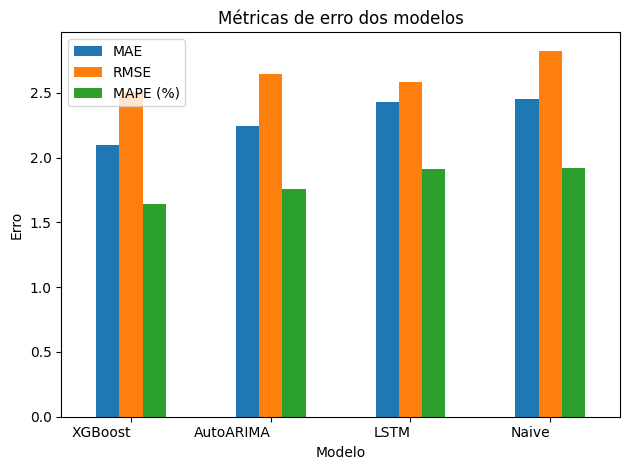

In [87]:
ax = df_erros.plot(kind='bar', y=['MAE', 'RMSE', 'MAPE (%)'], x='Modelo')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='right')
ax.set_title('Métricas de erro dos modelos')
ax.set_ylabel('Erro')
ax.get_figure().set_tight_layout(True)

Entre os modelos testados nos dados de validação, o XGBoost apresentou os menores erros e a maior precisão (98,36%) em comparação com os demais. No entanto, ao analisar o gráfico de previsões, observa-se que o modelo LSTM acompanha melhor a tendência dos valores reais em relação às previsões do XGBoost. Como a diferença de precisão entre os dois modelos é de apenas 0,27%, escolheríamos o LSTM com um lag de 3 semanas (15 dias úteis) como o modelo de previsão.